# 05 — Three MC SR significance candidates and VR2 validation (2mu2e)

Fix the three boundary WPs selected in the nominal **MC SR** and apply the same boundaries to **VR2 PP · DP · PD**.
The reference is **(mu iso, |Δφ|)=(0.30, 2.6)**. First compare the reference and the three candidates,
then present each WP's distributions, ABCD yields, scans, correlations, and MC SR results in the style of notebooks 03 and 04.

| Candidate | Mu isolation boundary | Δφ boundary [rad] |
|---|---:|---:|
| WP1 | 0.20 | 2.6 |
| WP2 | 0.20 | 2.7 |
| WP3 | 0.20 | 2.8 |

**Nominal DATA A remains blinded. Nominal DATA is neither projected nor aggregated.**
Do not add DD to VR2 or use an inclusive displacement selection.
These three candidates have already been selected using MC; this notebook does not reselect them using VR DATA closure.

Run with `Restart → Run All`. Read the original coffea inputs once per channel and partition the same planes using the three WPs.
For each WP, update the SR and VR boundaries, fixed-axis scans, composition, and correlations together.


In [1]:
from pathlib import Path
import sys

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "sidm"), None)
if SIDM_DIR is None:
    raise RuntimeError("Run this notebook from inside the sidm repository.")
if str(SIDM_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SIDM_DIR.parent))
NOTEBOOK_DIR = SIDM_DIR / "studies" / "ABCD_finalize"
INPUT_DIR = SIDM_DIR / "studies" / "ABCD_plane_summary"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

# Import coffea/pyarrow before defining NumPy 2 pickle compatibility aliases.
import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42,
                     "figure.max_open_warning": 0})
pd.set_option("display.max_columns", 20)

for helper in ("abcd_finalize_common.py", "abcd_finalize_plots.py",
               "abcd_finalize_common.py", "abcd_finalize_common.py"):
    if not (NOTEBOOK_DIR / helper).is_file():
        raise FileNotFoundError(NOTEBOOK_DIR / helper)
from abcd_finalize_common import finalize_wp_comparison_run_wp_comparison as run_wp_comparison, finalize_wp_comparison_make_wp_figures as make_wp_figures, finalize_wp_comparison_export_wp_comparison as export_wp_comparison

# Display notebook PNGs regardless of the significance helper's batch backend.
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42,
                     "figure.max_open_warning": 0})


## 1. Selections and fixed candidates

| Purpose | Displacement | Mjj [GeV] | Partner isolation |
|---|---|---|---|
| Nominal MC SR | DD | ≥150 | 0≤iso<0.5 |
| VR2 | PP · DP · PD | 150≤Mjj<300 | 0≤iso<0.5 |

LJ0=mu and LJ1=EGM. For mu, P means max pixel hits>2 and D means ≤2; for EGM, P means min lost hits<1 and D means ≥1.

**A=low iso/high Δφ**, B=high/high, C=low/low, and D=high/low.
A requires `iso < tx` and `|Δφ| ≥ ty`; values on a boundary belong to the high side.
There is no additional Δφ event preselection. Mass intervals include the lower edge and exclude the upper edge.
The (0.30, 2.6) in `CONFIG` is used to calculate the original reference; the actual candidates are listed in `WORKING_POINTS`.


In [2]:
TOPOLOGY = '2mu2e'
VR = 'VR2'
NOTEBOOK_NAME = '05_MuIso_DPhi_2mu2e_WP_comparison.ipynb'
OUTPUT_DIR = NOTEBOOK_DIR / '05_2mu2e_WP_comparison_outputs'
CONFIG = {
    'topology': TOPOLOGY, 'vr': VR, 'candidate_order': ['PP', 'DP', 'PD'],
    'output_dir': OUTPUT_DIR,
    'notebook_path': NOTEBOOK_DIR / NOTEBOOK_NAME,
    'sr_reference_dir': INPUT_DIR / '11_Optimized_ABCD_2mu2e_comparison_outputs',
    'bkg_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1',
    'signal_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_signal_merged_samples_v1',
    'data_dir': INPUT_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_data_merged_samples_v1',
    'current_hist': 'abcd6d_' + TOPOLOGY,
    'expected_current_channel': 'abcd6d_inclusive_' + TOPOLOGY + '_dxySpread_cosAlpha_mu_veto_eHEM',
    'mass_min': 150.0, 'mass_max': 300.0,
    'partner_iso_low': 0., 'partner_iso_high': .5,
    'tx': .3, 'ty': 2.6,
    'scan_mu_iso': [.05, .1, .15, .2, .25, .3, .4, .5, .75, 1., 2.],
    'scan_abs_dphi': [.5, 1., 1.5, 2., 2.2, 2.4, 2.6, 2.7, 2.8, 2.9, 3., 3.05, 3.1, np.pi],
    'closure_band': (.9, 1.1), 'min_neff': 10., 'purity_limit': .10,
}
print('Channel:', TOPOLOGY, '| VR:', VR, '| Categories:', CONFIG['candidate_order'], '| Output:', OUTPUT_DIR)

WORKING_POINTS = [(0.2, 2.6), (0.2, 2.7), (0.2, 2.8)]
display(pd.DataFrame(WORKING_POINTS, columns=["mu_iso", "abs_dphi"],
                     index=["WP1", "WP2", "WP3"]))


Channel: 2mu2e | VR: VR2 | Categories: ['PP', 'DP', 'PD'] | Output: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/05_2mu2e_WP_comparison_outputs


,mu_iso,abs_dphi
WP1,0.2,2.6
WP2,0.2,2.7
WP3,0.2,2.8


## 2. Significance, blinding, and uncertainty definitions

For each signal hypothesis, use its nominal MC SR A yield as $S$ and the background MC yield in the same region as $B$.

$$ Z_A=\sqrt{2\left[(S+B)\ln(1+S/B)-S\right]}. $$

Evaluate the **60 signal hypotheses matching the channel** individually and compare the median of their $Z_A(\mathrm{WP})/Z_A(\mathrm{reference})$ ratios.
Do not sum signal hypotheses. Leave ratios undefined for hypotheses with reference Z=0.
Also inspect an effective on/off Asimov diagnostic using $\sigma_B^2=\sum w^2$.
The formulas follow [Cowan's counting-experiment note, Eqs. (10) and (20)](https://www.pp.rhul.ac.uk/~cowan/stat/medsig/medsigNote.pdf).
Retain the stored production normalization without rescaling cross sections.
This is not the discovery significance of the full ABCD likelihood. The sensitivity metric excludes closure nuisance parameters, signal MC uncertainties, and sideband signal leakage.

- **DATA WP gate:** Require $S/B_{MC}<0.10$ in every ABCD region for all 60 2Mu2E and 60 4Mu hypotheses at 200–1000 GeV. Each background denominator must be valid and positive.
- **DATA 2D bin mask:** In the bins used by the plots, after merging the iso tail/overflow and angle flow, mask bins where the maximum $S/B_{MC}$ across the 120 signals is $\geq0.10$ or MC support is invalid. Exclude masked DATA from the color-range calculation as well.
- The bin mask applies only to the 2D distribution display. ABCD yields and scans use the existing region-level gate and are not recalculated after removing masked bins.
- Show only MC in the MC SR. Do not calculate VR2 DD or nominal DATA.
- Display the iso scan over 0–2 and the Δφ scan over 0–π, using the 11×14=154 native boundary points. Exclude the degenerate 0 boundaries from the calculation.

As in notebooks 03 and 04, apply first-order uncertainty propagation for independent regions to $P=BC/D$ and $\kappa=A/P$.

$$\sigma_P=|P|\sqrt{(\sigma_B/B)^2+(\sigma_C/C)^2+(\sigma_D/D)^2},\qquad
\sigma_\kappa=|\kappa|\sqrt{(\sigma_A/A)^2+(\sigma_P/P)^2}.$$

For each region, $\sigma_X=\sqrt{\sum w^2}$ and $N_\mathrm{eff}=(\sum w)^2/\sum w^2$.
These formulas apply to positive, nonzero region yields. Leave D≤0 undefined;
retain the existing zero-error convention for B or C=0 together with its status flag. Do not interpret this as a precise zero prediction.
The green ±10% κ band is a reference range; nearby WPs and scan points share events.


## 3. Recalculation from original inputs and comparison with the reference

Recalculate the full MC SR and VR scans and purities using the original 18 backgrounds and 120 signals.
Process only approved VR DATA, then apply the same boundaries at each of the three fixed WPs.
Distinguish the 10–90% spread across signal hypotheses in the summary plots from statistical error bars.


In [3]:
results = run_wp_comparison(CONFIG, WORKING_POINTS)
tables = results['tables']
with pd.option_context('display.max_columns', None):
    display(results['working_points'])
    summary = tables['significance_summary']
    columns = [name for name in ['wp', 'tx', 'ty', 'b', 'sigma_b', 'neff_b',
                               'z_known_b_ratio_median', 'z_known_b_ratio_q10',
                               'z_known_b_ratio_q90', 'z_mc_stat_diagnostic_ratio_median']
               if name in summary]
    display(summary[columns])
    display(tables['distribution_blinding_summary'])
    display(tables['validation'])


MC 20/138 (18 backgrounds + 120 individual signal hypotheses)


MC 40/138 (18 backgrounds + 120 individual signal hypotheses)


MC 60/138 (18 backgrounds + 120 individual signal hypotheses)


MC 80/138 (18 backgrounds + 120 individual signal hypotheses)


MC 100/138 (18 backgrounds + 120 individual signal hypotheses)


MC 120/138 (18 backgrounds + 120 individual signal hypotheses)


... (5 outputs left out)

,wp,tx,ty
0,Reference,0.3,2.6
1,WP1,0.2,2.6
2,WP2,0.2,2.7
3,WP3,0.2,2.8


,wp,tx,ty,b,sigma_b,neff_b,z_known_b_ratio_median,z_known_b_ratio_q10,z_known_b_ratio_q90,z_mc_stat_diagnostic_ratio_median
0,Reference,0.3,2.6,24.924437,12.760609,3.815118,1.000000,1.000000,1.000000,1.000000
1,WP1,0.2,2.6,2.265319,1.149726,3.882130,3.155835,2.288415,3.299701,6.808027
2,WP2,0.2,2.7,2.162417,1.145899,3.561113,3.116885,2.273151,3.305740,6.686955
3,WP3,0.2,2.8,2.133242,1.145528,3.467919,2.968342,2.205596,3.216778,6.349247


,wp,plane,tx,ty,integrated_gate_approved,displayed_bins,approved_bins,blinded_bins,contamination_blinded_bins,unsupported_background_bins
0,Reference,PP,0.3,2.6,True,154,128,26,5,21
1,Reference,DP,0.3,2.6,True,154,44,110,3,107
2,Reference,PD,0.3,2.6,True,154,137,17,8,9
3,WP1,PP,0.2,2.6,True,154,128,26,5,21
4,WP1,DP,0.2,2.6,True,154,44,110,3,107
5,WP1,PD,0.2,2.6,True,154,137,17,8,9
6,WP2,PP,0.2,2.7,True,154,128,26,5,21
7,WP2,DP,0.2,2.7,True,154,44,110,3,107
8,WP2,PD,0.2,2.7,True,154,137,17,8,9
9,WP3,PP,0.2,2.8,True,154,128,26,5,21


,wp,plane,source,tx,ty,check,passed
0,WP1,PP,MC,0.2,2.6,Selected closure equals validated full grid,True
1,WP1,PP,DATA,0.2,2.6,Selected closure equals validated full grid,True
2,WP1,DP,MC,0.2,2.6,Selected closure equals validated full grid,True
3,WP1,DP,DATA,0.2,2.6,Selected closure equals validated full grid,True
4,WP1,PD,MC,0.2,2.6,Selected closure equals validated full grid,True
5,WP1,PD,DATA,0.2,2.6,Selected closure equals validated full grid,True
6,WP1,VR,MC / approved VR DATA,0.2,2.6,Scans hold the other selected WP boundary fixed,True
7,WP1,SR,MC / approved VR DATA,0.2,2.6,Scans hold the other selected WP boundary fixed,True
8,WP1,SR,MC,0.2,2.6,Same SR/VR WP; direct MC partition; no nominal...,True
9,WP2,PP,MC,0.2,2.7,Selected closure equals validated full grid,True


In [4]:
figures = make_wp_figures(results, CONFIG)
figure_lookup = {stem: figure for figure, stem in figures}
assert len(figures) == len(figure_lookup) == 66
summary_stems = [stem for _, stem in figures if not stem.startswith(('wp1_', 'wp2_', 'wp3_'))]
assert len(summary_stems) == 3
for figure, _ in figures:
    plt.close(figure)


### 3.1. MC SR sensitivity of the reference and the three WPs


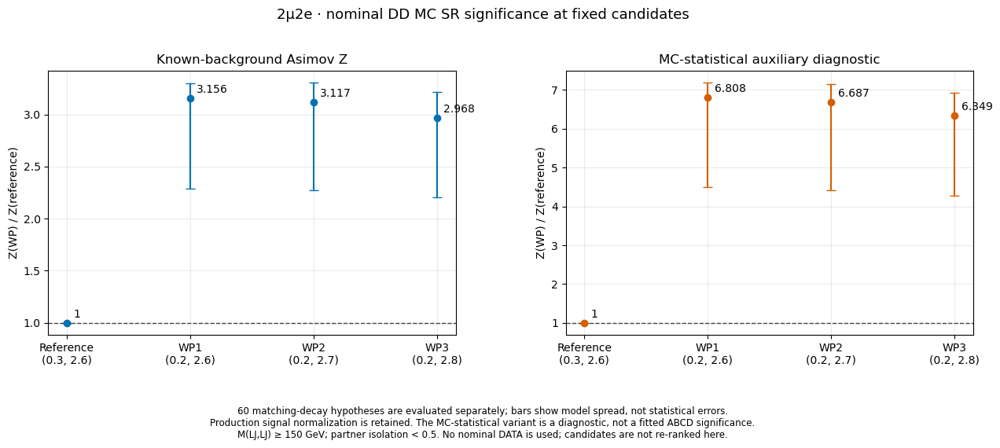

In [5]:
display(figure_lookup[summary_stems[0]])


### 3.2. Nominal MC SR statistical diagnostics


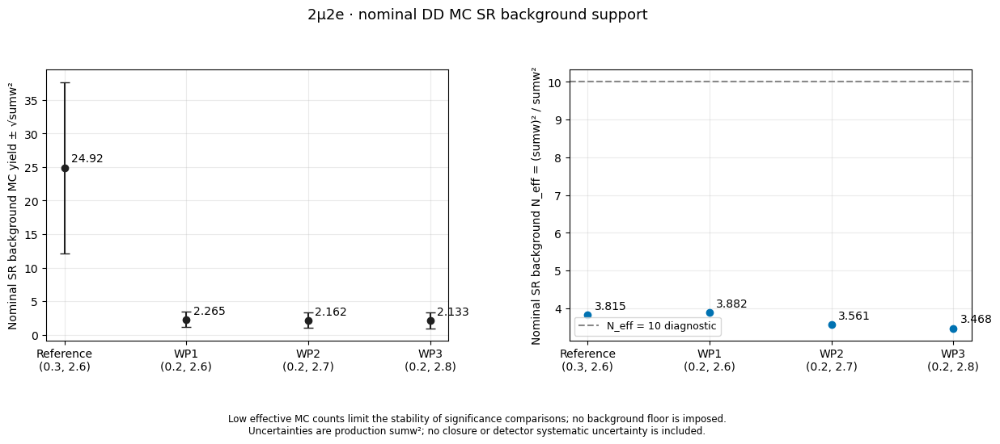

In [6]:
display(figure_lookup[summary_stems[1]])


### 3.3. VR2 closure comparison with identical boundaries


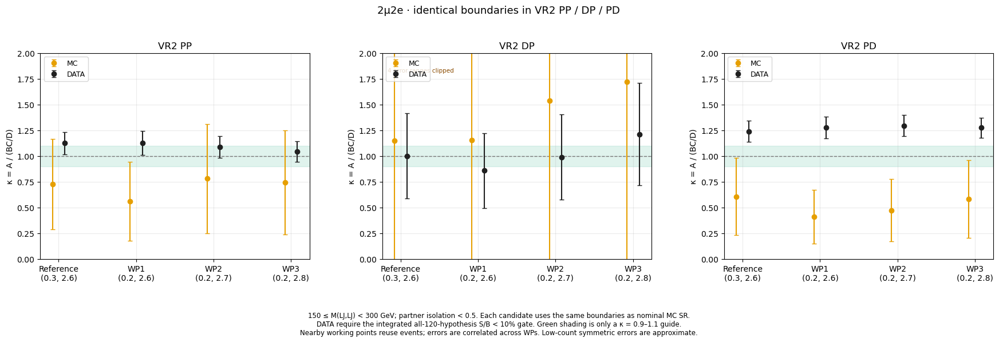

In [7]:
display(figure_lookup[summary_stems[2]])


## 4. WP1 — (mu iso, |Δφ|)=(0.20, 2.6)

Apply **the same (0.20, 2.6) boundaries to VR2 PP·DP·PD and the nominal MC SR** in this section.
Fix Δφ at **2.6** for the iso scan and iso at **0.20** for the Δφ scan.
The 154-point 2D κ map uses the shared scan; only the selected-WP marker changes.


In [8]:
point = results['points']['WP1']
with pd.option_context('display.max_columns', None):
    display(point['tables']['selection'][['plane', 'state0', 'state1', 'mass_low',
                                         'mass_high', 'partner_iso_high', 'tx', 'ty']])
    display(point['tables']['closure'][['plane', 'source', 'A', 'B', 'C', 'D',
                                       'pred', 'pred_error', 'kappa', 'kappa_error',
                                       'neff_min', 'approved', 'status']])


,plane,state0,state1,mass_low,mass_high,partner_iso_high,tx,ty
0,PP,P,P,150.0,300.0,0.5,0.2,2.6
1,DP,D,P,150.0,300.0,0.5,0.2,2.6
2,PD,P,D,150.0,300.0,0.5,0.2,2.6


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,approved,status
0,PP,MC,386.473228,1363.486233,231.398151,457.809645,689.168952,362.268230,0.560782,0.384896,5.134359,True,LOW_STAT_SIDEBAND
1,PP,DATA,460.000000,1036.000000,185.000000,471.000000,406.921444,37.502615,1.130439,0.116757,185.000000,True,OK
2,DP,MC,7.327512,34.065042,3.334575,17.879139,6.353350,7.090199,1.153330,1.728229,1.000000,True,LOW_STAT_SIDEBAND
3,DP,DATA,23.000000,44.000000,14.000000,23.000000,26.782609,9.936099,0.858766,0.365468,14.000000,True,OK
4,PD,MC,219.921048,1216.665168,418.119992,948.745302,536.194518,281.566180,0.410152,0.260033,6.020186,True,LOW_STAT_SIDEBAND
5,PD,DATA,866.000000,999.000000,356.000000,524.000000,678.709924,51.324055,1.275950,0.105782,356.000000,True,OK


### 4.1. MC and DATA closure comparison at the fixed WP


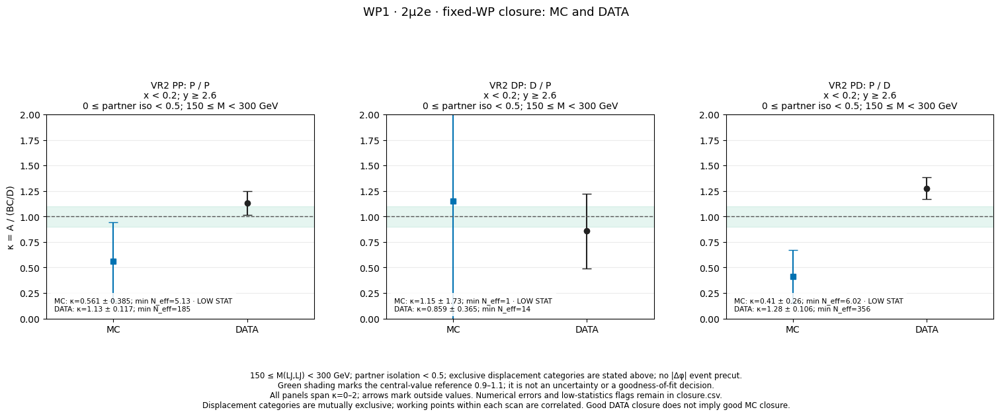

In [9]:
display(figure_lookup['wp1_combined_VR_selected_closure'])


### 4.2. Maximum S/B across 120 signals in each ABCD region


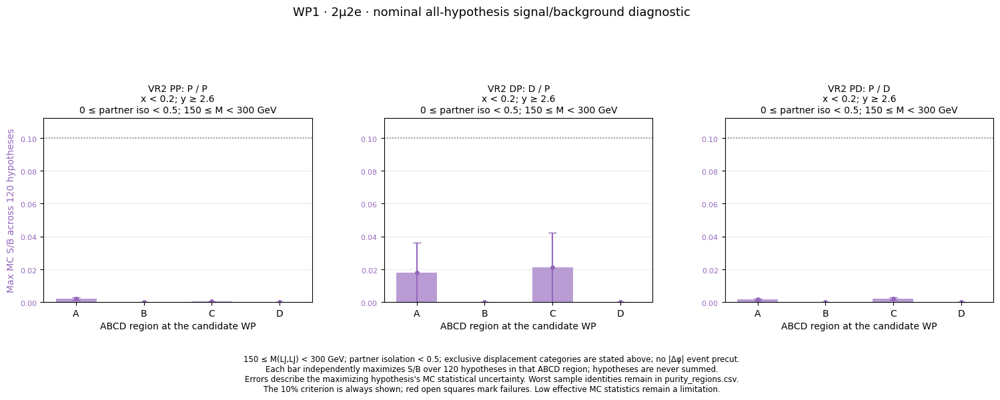

In [10]:
display(figure_lookup['wp1_mc_VR_purity_regions'])


### 4.3. DATA 2D distributions — bin-level blinding


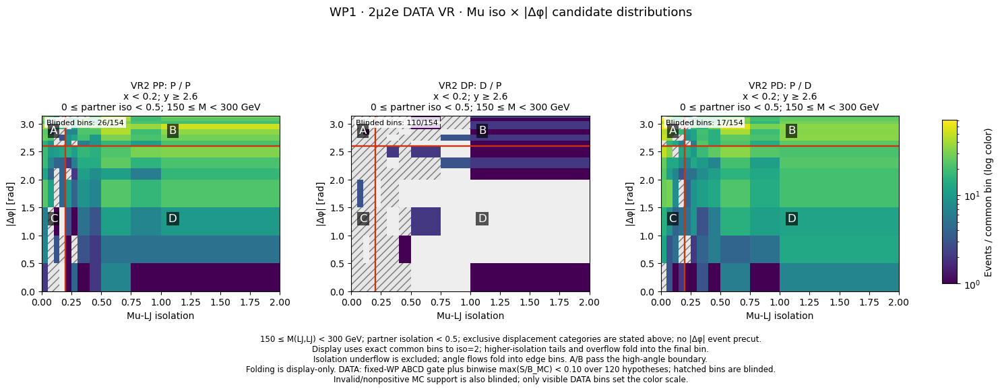

In [11]:
display(figure_lookup['wp1_data_VR_planes'])


### 4.4. DATA observed A, predicted BC/D, and κ


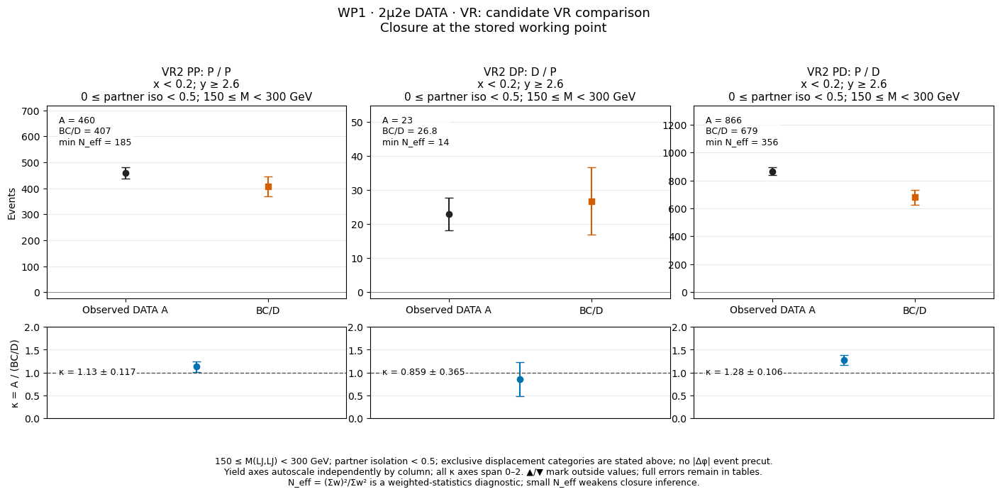

In [12]:
display(figure_lookup['wp1_data_VR_selected_closure'])


### 4.5. DATA isolation boundary scan


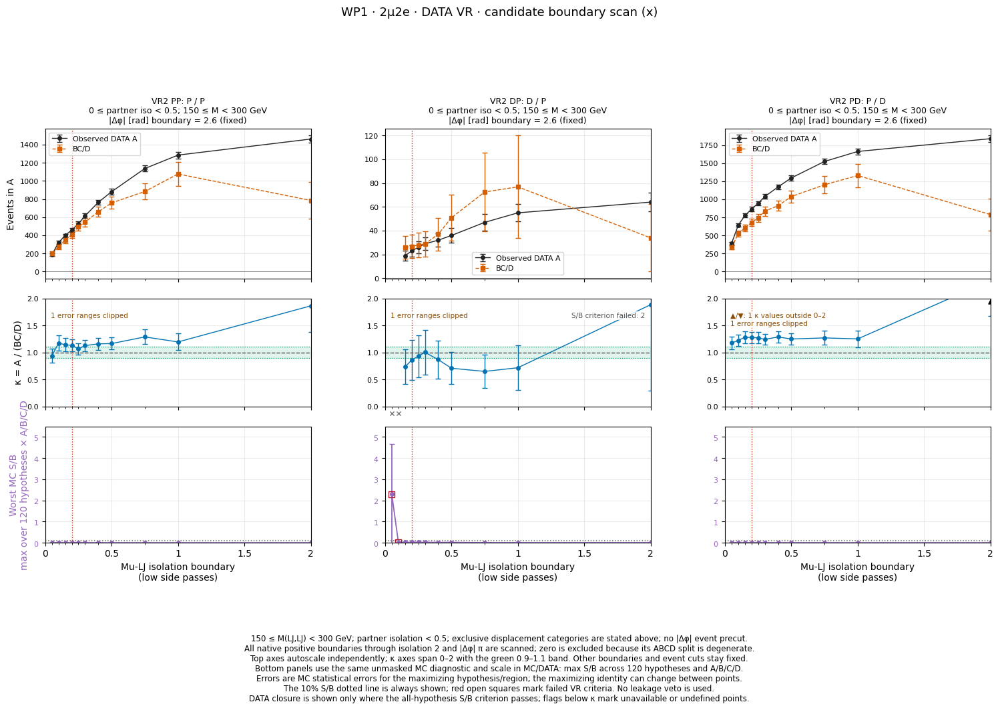

In [13]:
display(figure_lookup['wp1_data_VR_x_scan'])


### 4.6. DATA Δφ boundary scan


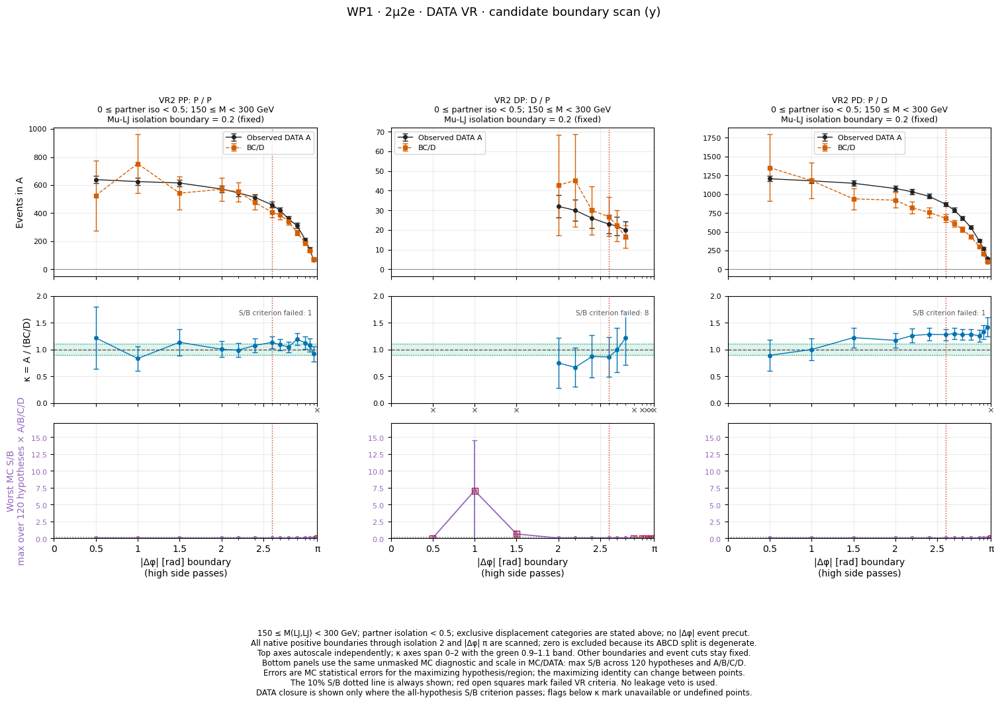

In [14]:
display(figure_lookup['wp1_data_VR_y_scan'])


### 4.7. DATA 154-point κ map


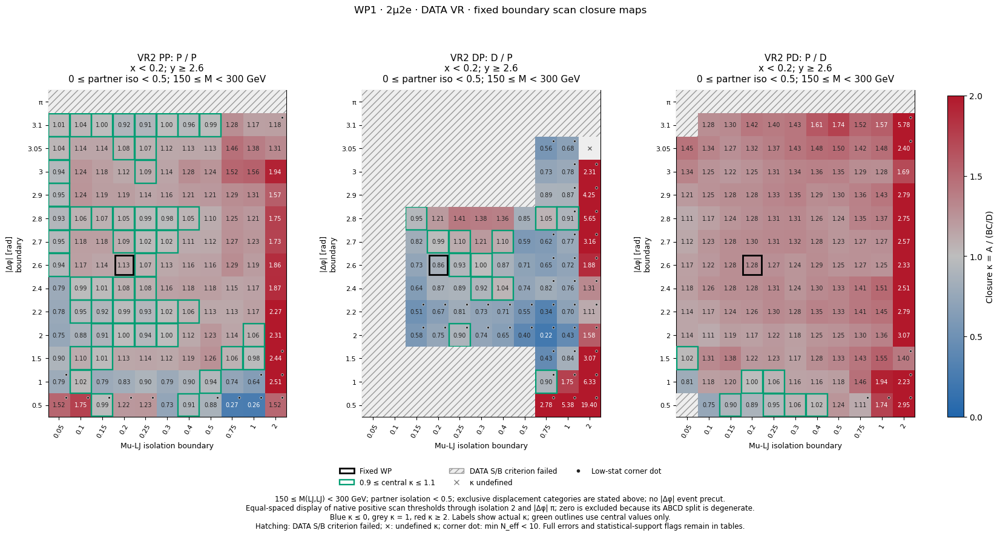

In [15]:
display(figure_lookup['wp1_data_VR_closure_grid'])


### 4.8. MC 2D distributions


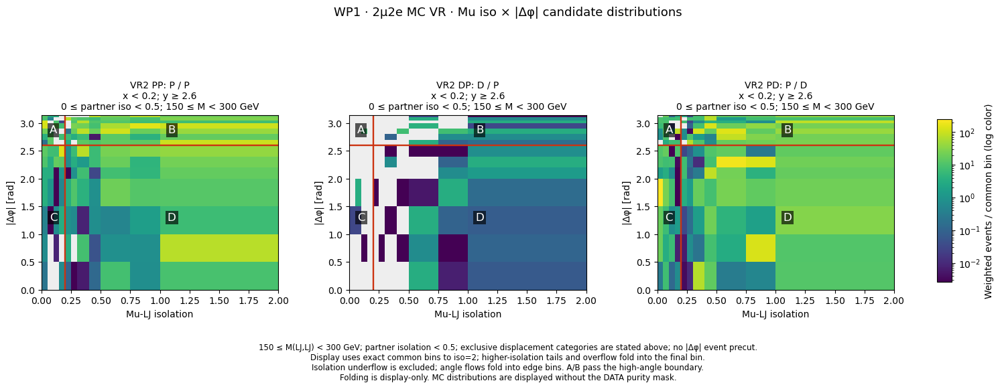

In [16]:
display(figure_lookup['wp1_mc_VR_planes'])


### 4.9. MC observed A, predicted BC/D, and κ


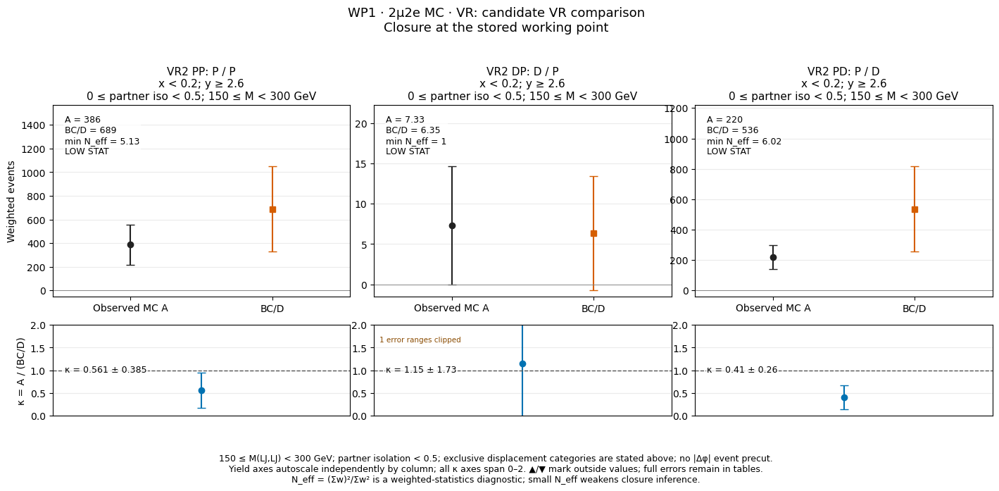

In [17]:
display(figure_lookup['wp1_mc_VR_selected_closure'])


### 4.10. MC isolation boundary scan


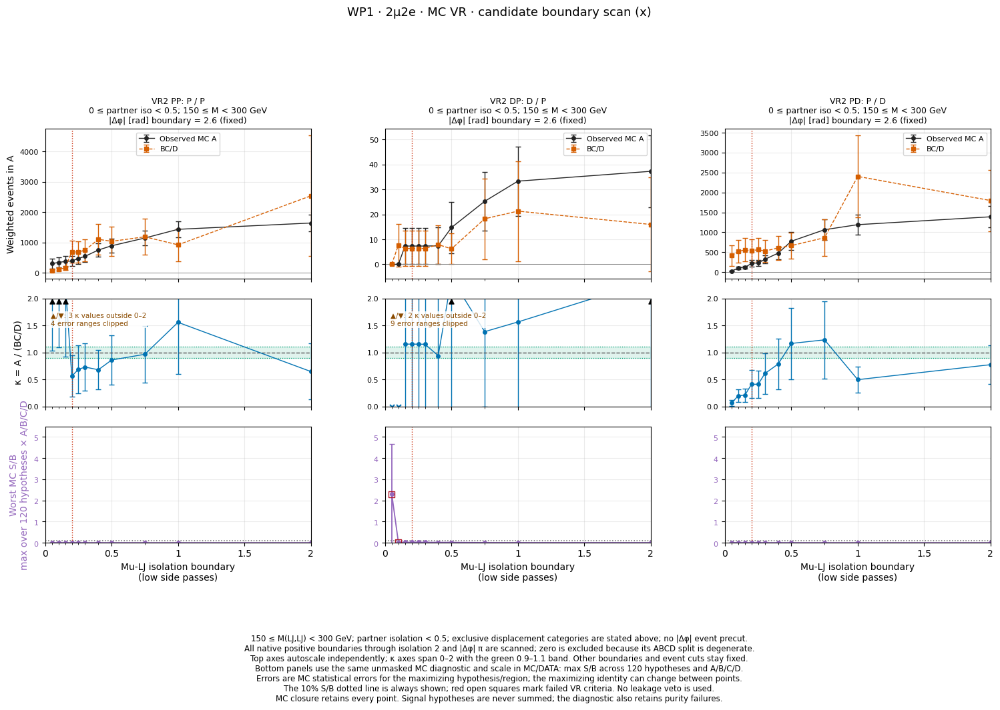

In [18]:
display(figure_lookup['wp1_mc_VR_x_scan'])


### 4.11. MC Δφ boundary scan


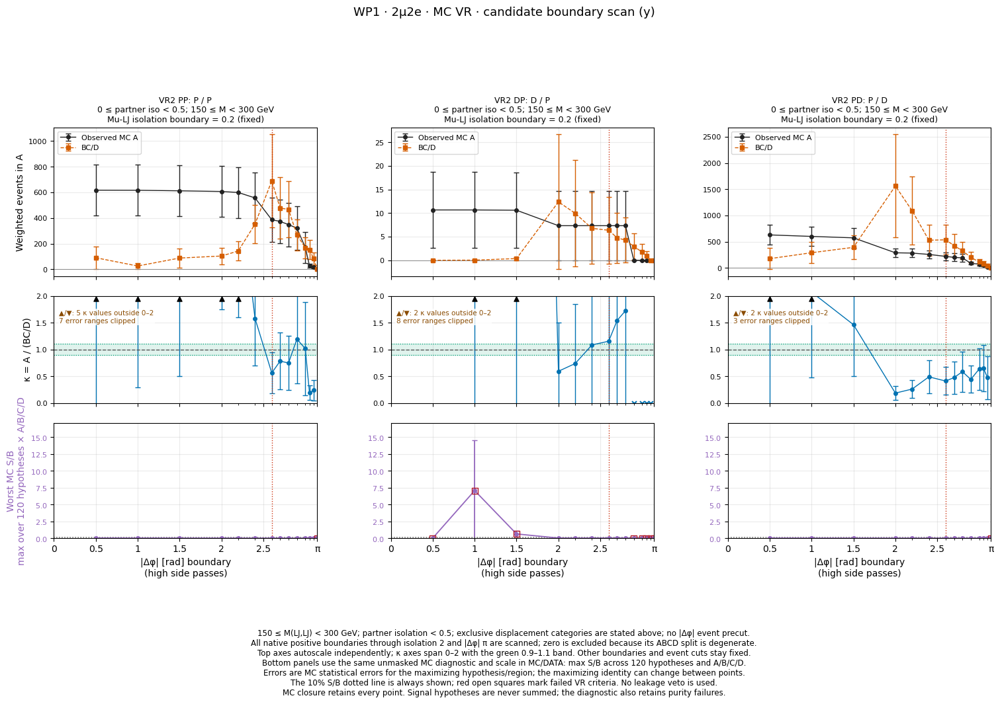

In [19]:
display(figure_lookup['wp1_mc_VR_y_scan'])


### 4.12. MC 154-point κ map


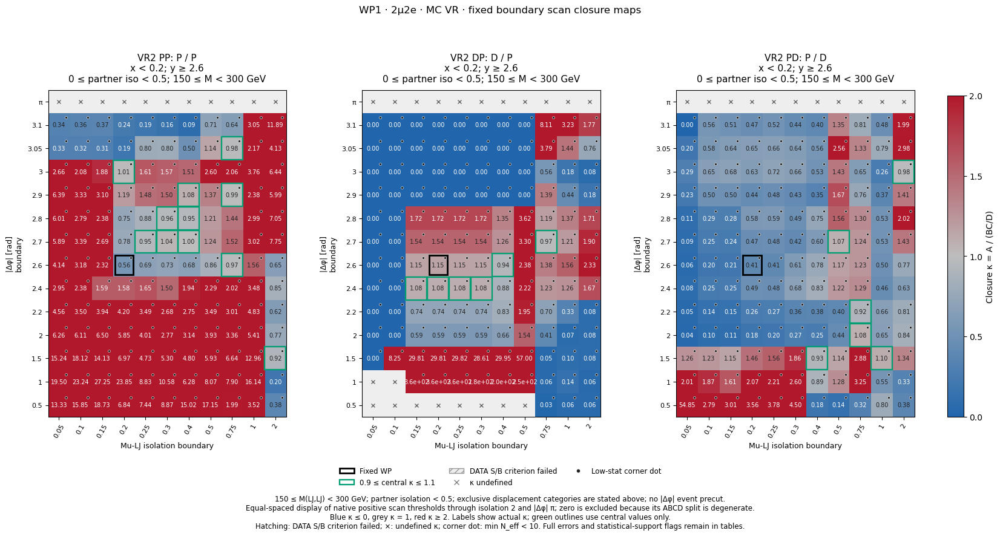

In [20]:
display(figure_lookup['wp1_mc_VR_closure_grid'])


### 4.13. MC background composition


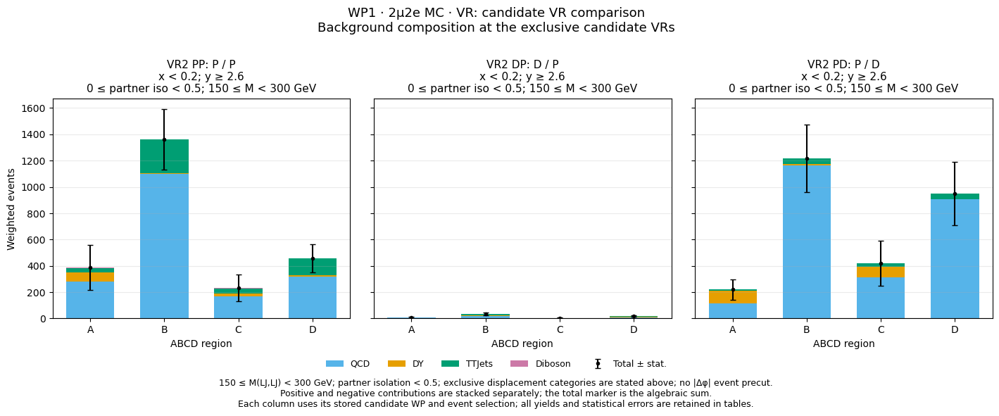

In [21]:
display(figure_lookup['wp1_mc_VR_composition'])


### 4.14. MC ABCD effective counts


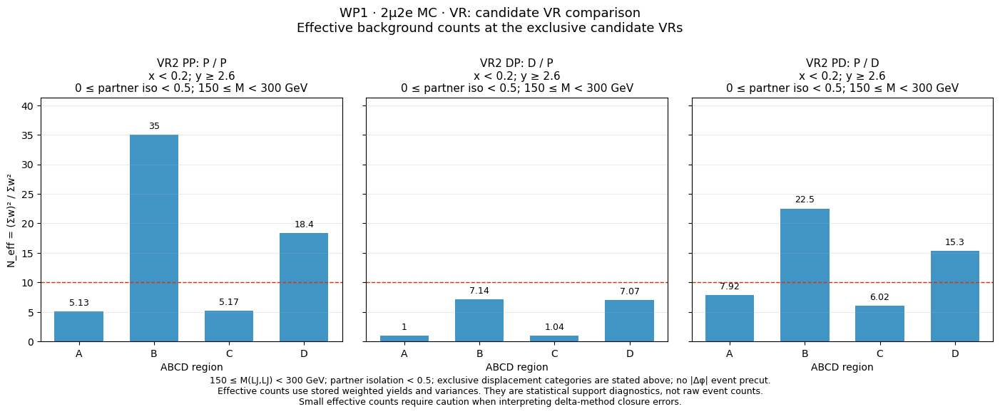

In [22]:
display(figure_lookup['wp1_mc_VR_effective_counts'])


### 4.15. DATA All/A/B/C/D correlations


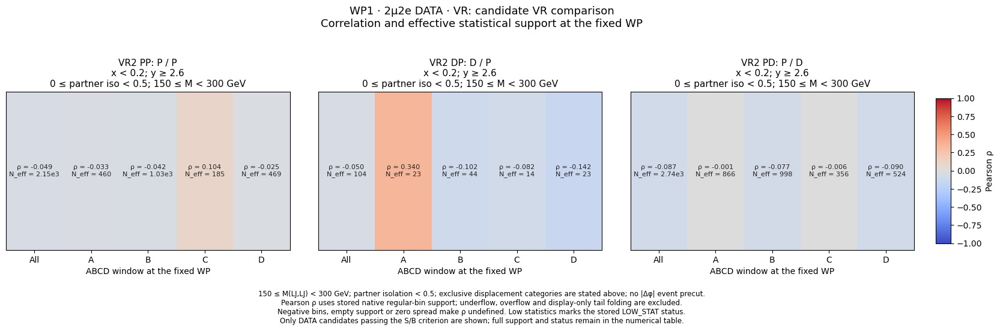

In [23]:
display(figure_lookup['wp1_data_VR_correlations'])


### 4.16. MC All/A/B/C/D correlations


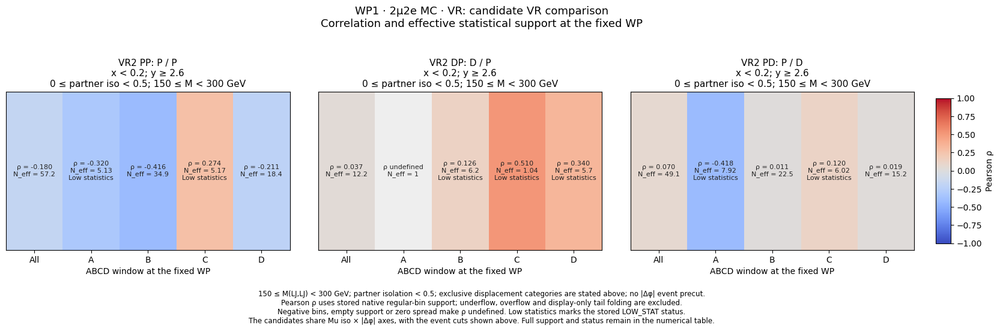

In [24]:
display(figure_lookup['wp1_mc_VR_correlations'])


### 4.17. Nominal MC SR at the same WP

Retain DD, Mjj≥150 GeV, and 0≤partner iso<0.5.
Exclude nominal DATA. Partition the SR using the same (0.20, 2.6) boundaries as the VR.


In [25]:
sr = results['points']['WP1']['sr_reference']
with pd.option_context('display.max_columns', None):
    display(sr['tables']['closure'][['plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                     'pred', 'pred_error', 'kappa', 'kappa_error',
                                     'neff_min', 'status']])


,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
48,SR,MC,0.2,2.6,2.265319,166.911563,11.821221,56.095324,35.174026,36.262028,0.064403,0.074005,1.955015,LOW_STAT_SIDEBAND


### 4.18. Nominal MC SR 2D distributions


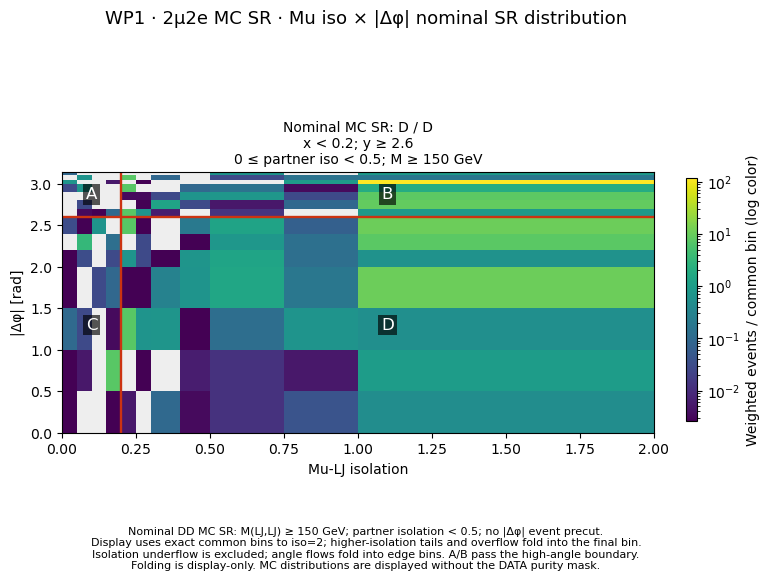

In [26]:
display(figure_lookup['wp1_mc_SR_planes'])


### 4.19. Nominal MC SR ABCD closure


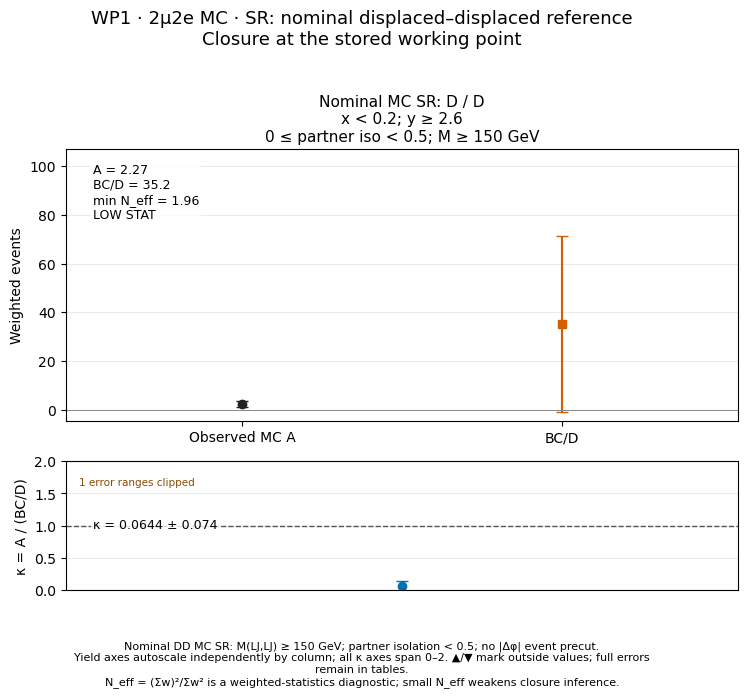

In [27]:
display(figure_lookup['wp1_mc_SR_selected_closure'])


### 4.20. Nominal MC SR isolation boundary scan


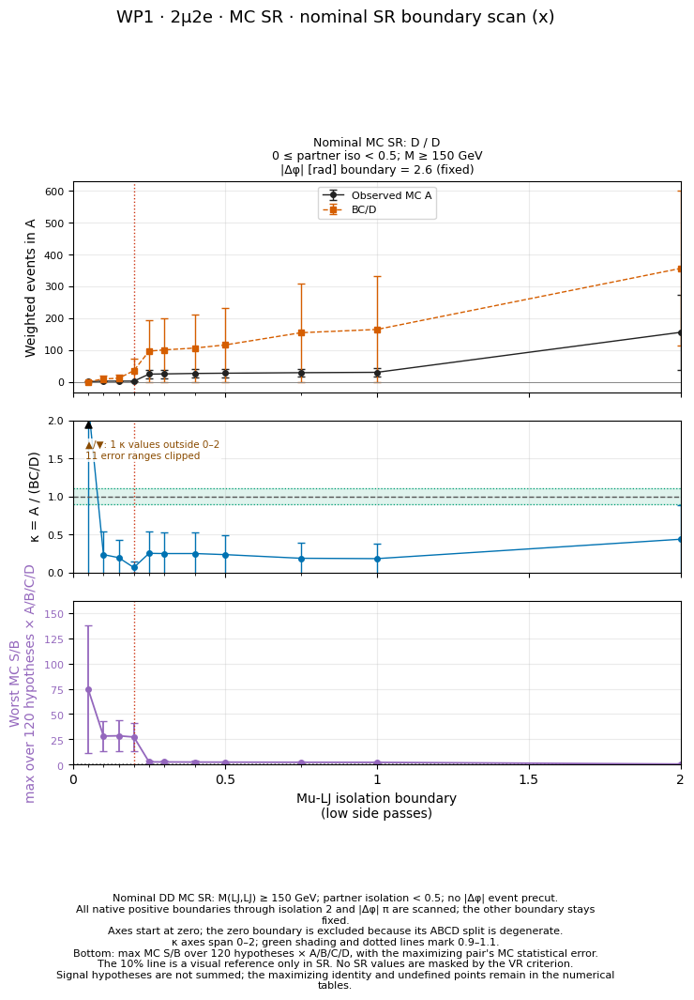

In [28]:
display(figure_lookup['wp1_mc_SR_x_scan'])


### 4.21. Nominal MC SR Δφ boundary scan


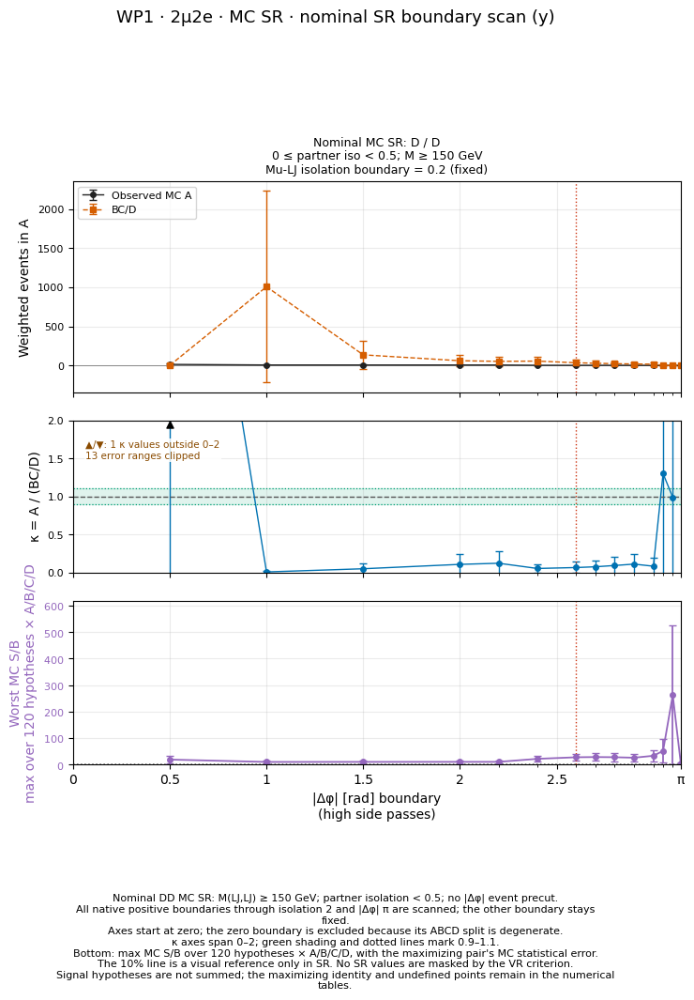

In [29]:
display(figure_lookup['wp1_mc_SR_y_scan'])


### 4.22. Nominal MC SR 154-point κ map


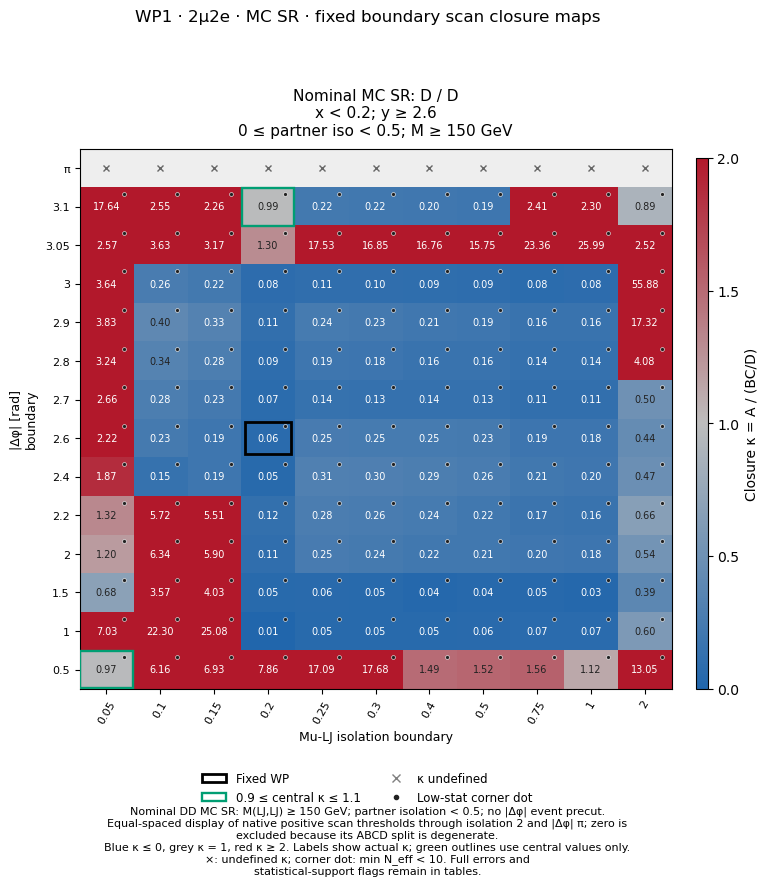

In [30]:
display(figure_lookup['wp1_mc_SR_closure_grid'])


## 5. WP2 — (mu iso, |Δφ|)=(0.20, 2.7)

Apply **the same (0.20, 2.7) boundaries to VR2 PP·DP·PD and the nominal MC SR** in this section.
Fix Δφ at **2.7** for the iso scan and iso at **0.20** for the Δφ scan.
The 154-point 2D κ map uses the shared scan; only the selected-WP marker changes.


In [31]:
point = results['points']['WP2']
with pd.option_context('display.max_columns', None):
    display(point['tables']['selection'][['plane', 'state0', 'state1', 'mass_low',
                                         'mass_high', 'partner_iso_high', 'tx', 'ty']])
    display(point['tables']['closure'][['plane', 'source', 'A', 'B', 'C', 'D',
                                       'pred', 'pred_error', 'kappa', 'kappa_error',
                                       'neff_min', 'approved', 'status']])


,plane,state0,state1,mass_low,mass_high,partner_iso_high,tx,ty
0,PP,P,P,150.0,300.0,0.5,0.2,2.7
1,DP,D,P,150.0,300.0,0.5,0.2,2.7
2,PD,P,D,150.0,300.0,0.5,0.2,2.7


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,approved,status
0,PP,MC,373.484514,1204.470734,244.386865,616.825143,477.212757,239.615200,0.782637,0.530776,4.811809,True,LOW_STAT_SIDEBAND
1,PP,DATA,420.000000,952.000000,225.000000,555.000000,385.945946,32.967706,1.088235,0.107055,225.000000,True,OK
2,DP,MC,7.327512,30.542516,3.334575,21.401664,4.758803,5.317970,1.539780,2.309060,1.000000,True,LOW_STAT_SIDEBAND
3,DP,DATA,22.000000,40.000000,15.000000,27.000000,22.222222,7.972289,0.990000,0.413149,15.000000,True,OK
4,PD,MC,201.988810,1069.813199,436.052230,1095.597270,425.790063,216.891980,0.474386,0.302338,6.521161,True,LOW_STAT_SIDEBAND
5,PD,DATA,789.000000,890.000000,433.000000,633.000000,608.799368,43.103869,1.295993,0.102705,433.000000,True,OK


### 5.1. MC and DATA closure comparison at the fixed WP


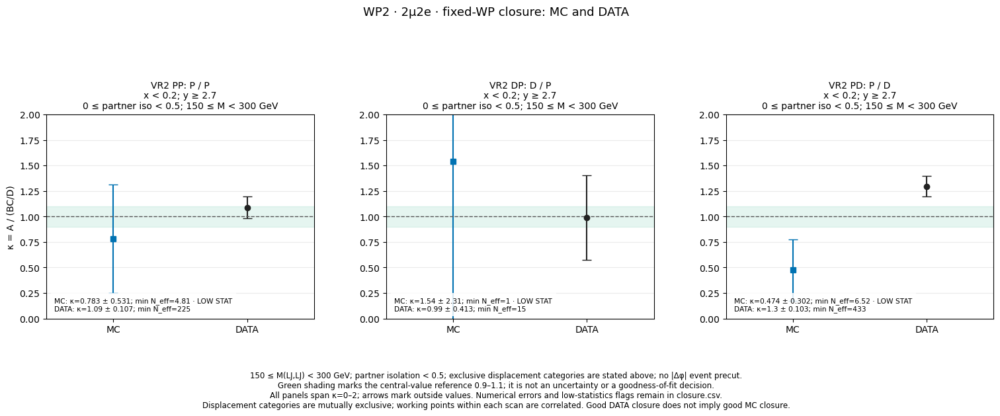

In [32]:
display(figure_lookup['wp2_combined_VR_selected_closure'])


### 5.2. Maximum S/B across 120 signals in each ABCD region


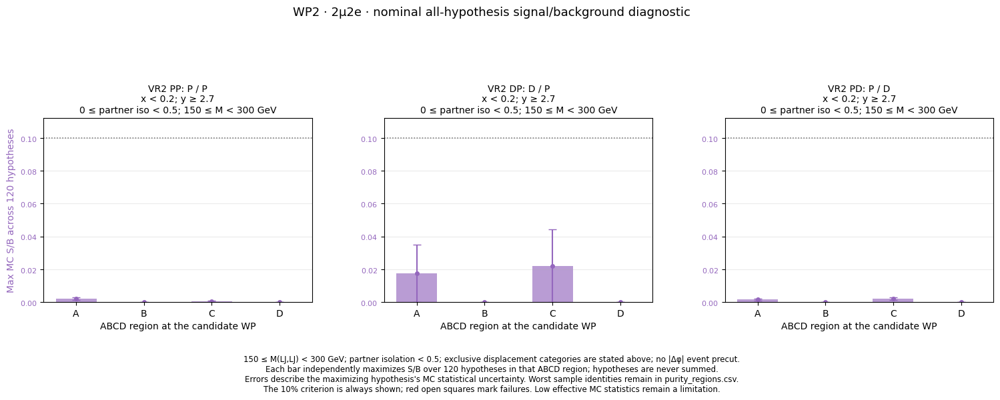

In [33]:
display(figure_lookup['wp2_mc_VR_purity_regions'])


### 5.3. DATA 2D distributions — bin-level blinding


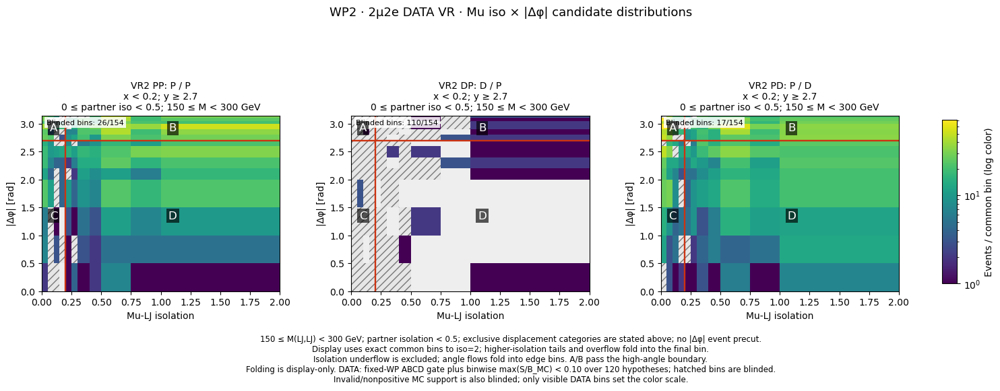

In [34]:
display(figure_lookup['wp2_data_VR_planes'])


### 5.4. DATA observed A, predicted BC/D, and κ


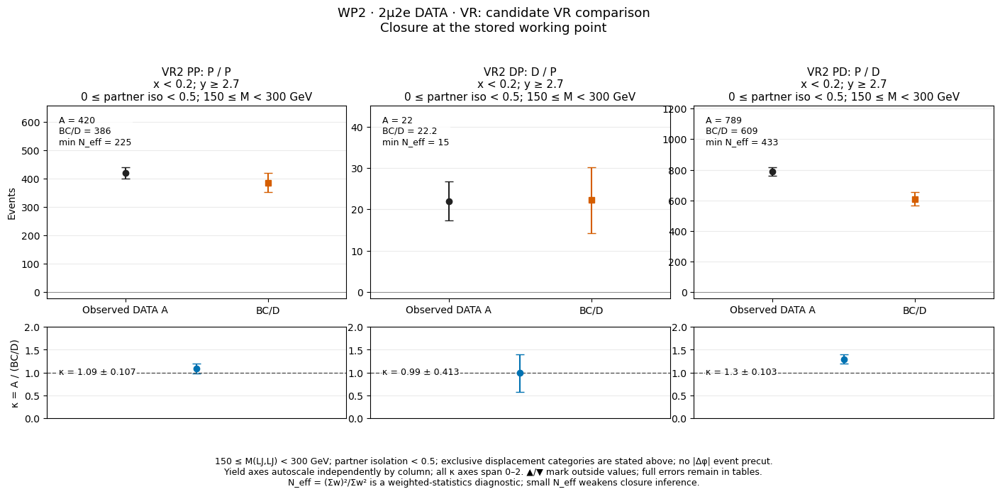

In [35]:
display(figure_lookup['wp2_data_VR_selected_closure'])


### 5.5. DATA isolation boundary scan


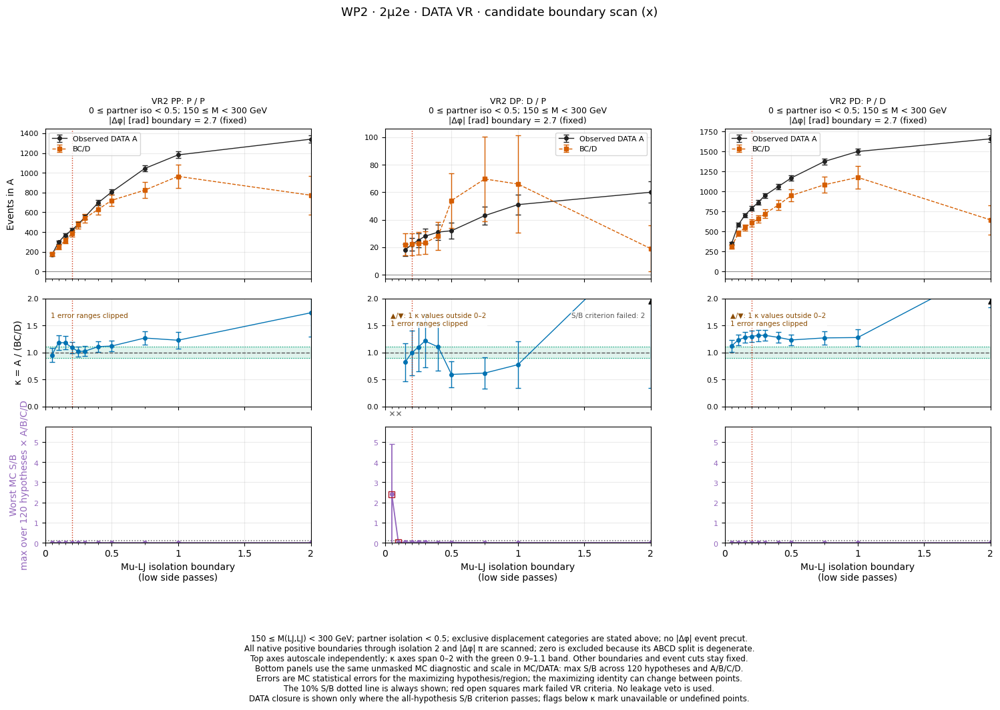

In [36]:
display(figure_lookup['wp2_data_VR_x_scan'])


### 5.6. DATA Δφ boundary scan


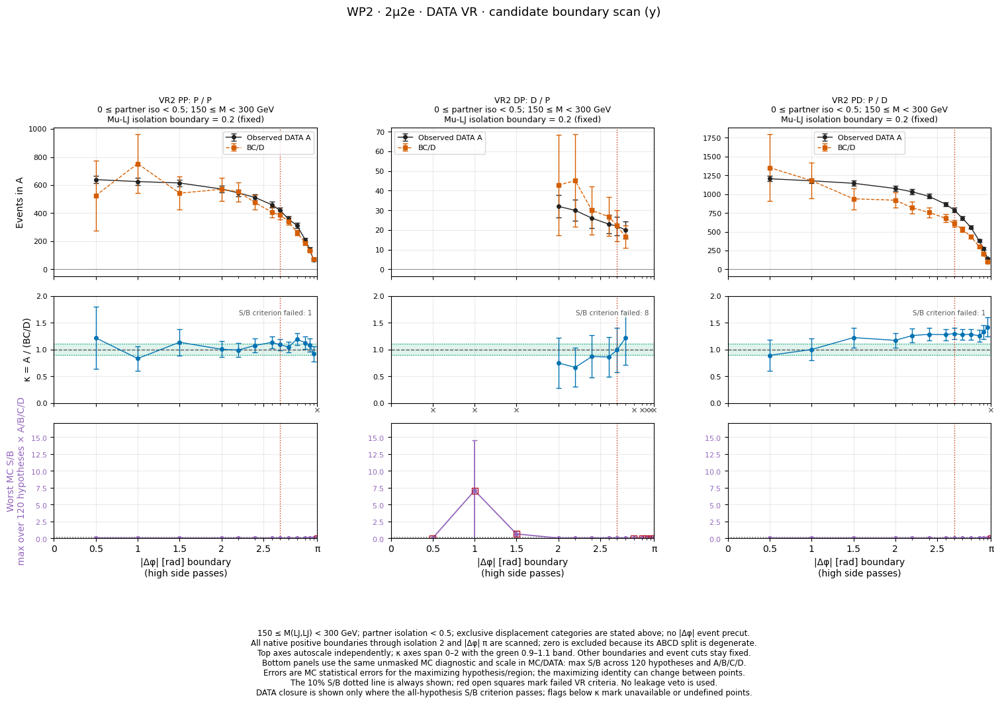

In [37]:
display(figure_lookup['wp2_data_VR_y_scan'])


### 5.7. DATA 154-point κ map


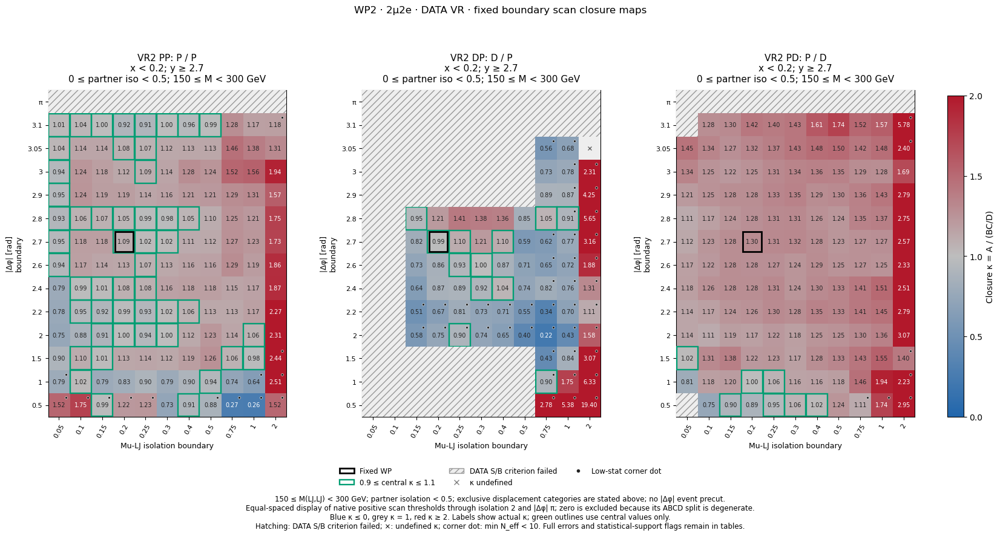

In [38]:
display(figure_lookup['wp2_data_VR_closure_grid'])


### 5.8. MC 2D distributions


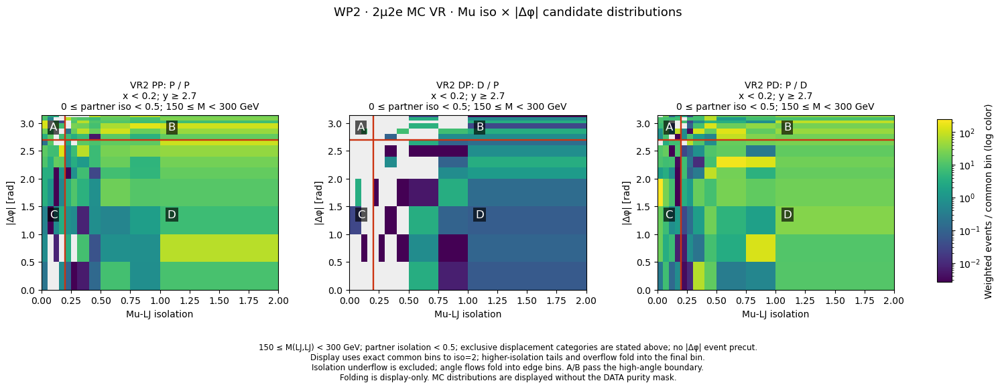

In [39]:
display(figure_lookup['wp2_mc_VR_planes'])


### 5.9. MC observed A, predicted BC/D, and κ


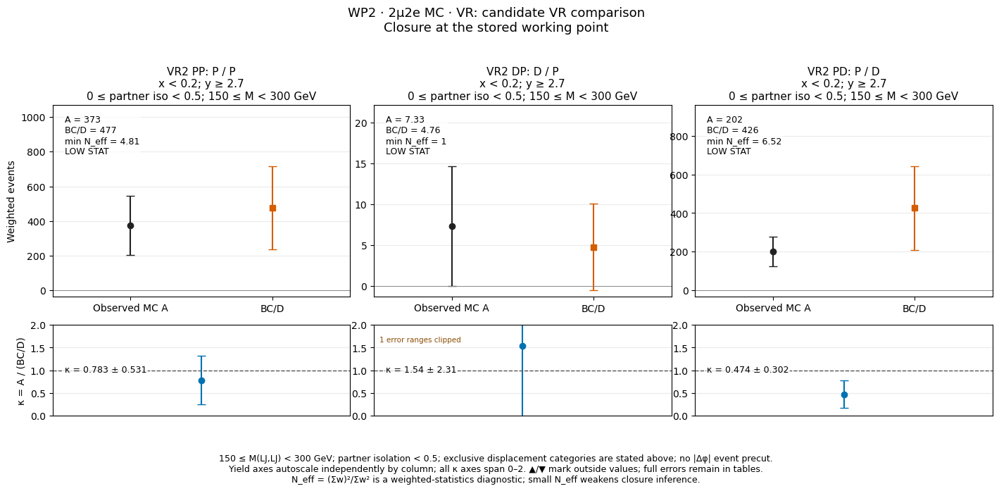

In [40]:
display(figure_lookup['wp2_mc_VR_selected_closure'])


### 5.10. MC isolation boundary scan


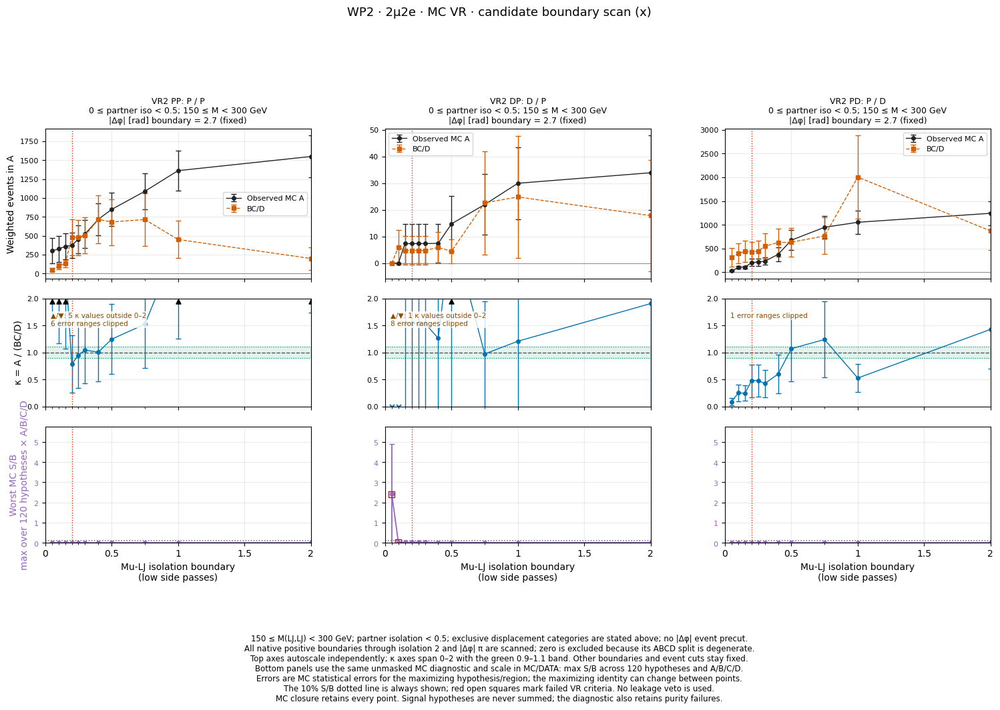

In [41]:
display(figure_lookup['wp2_mc_VR_x_scan'])


### 5.11. MC Δφ boundary scan


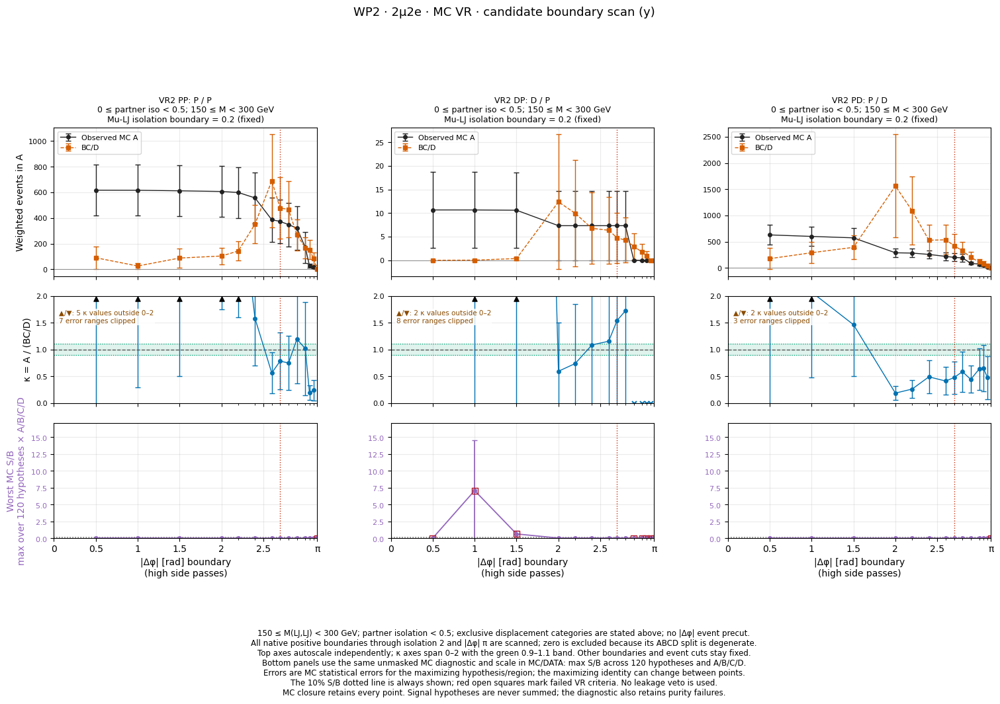

In [42]:
display(figure_lookup['wp2_mc_VR_y_scan'])


### 5.12. MC 154-point κ map


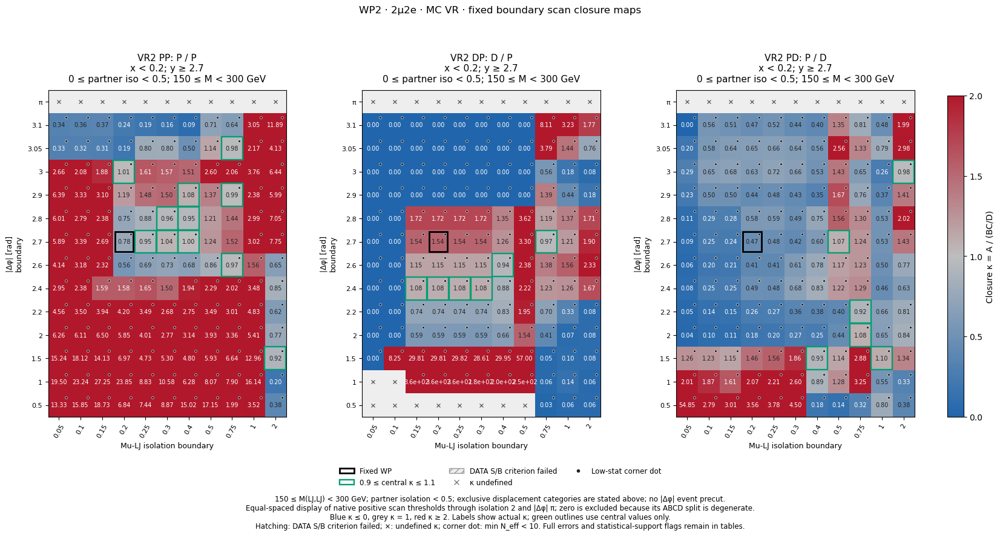

In [43]:
display(figure_lookup['wp2_mc_VR_closure_grid'])


### 5.13. MC background composition


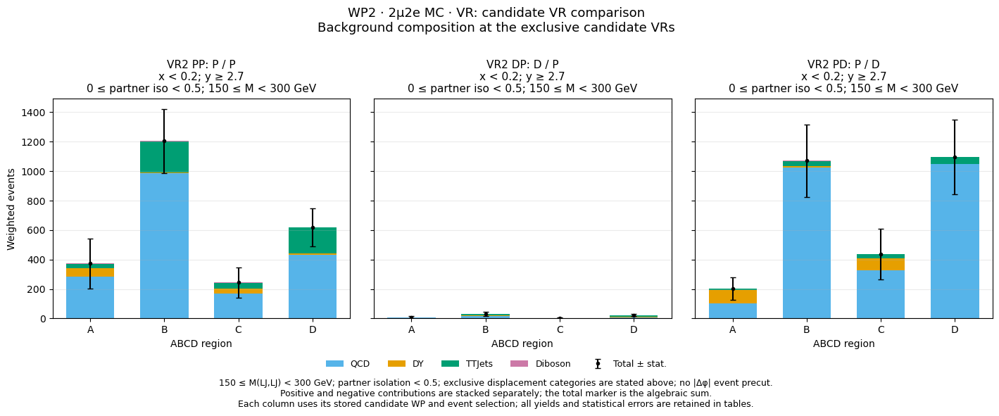

In [44]:
display(figure_lookup['wp2_mc_VR_composition'])


### 5.14. MC ABCD effective counts


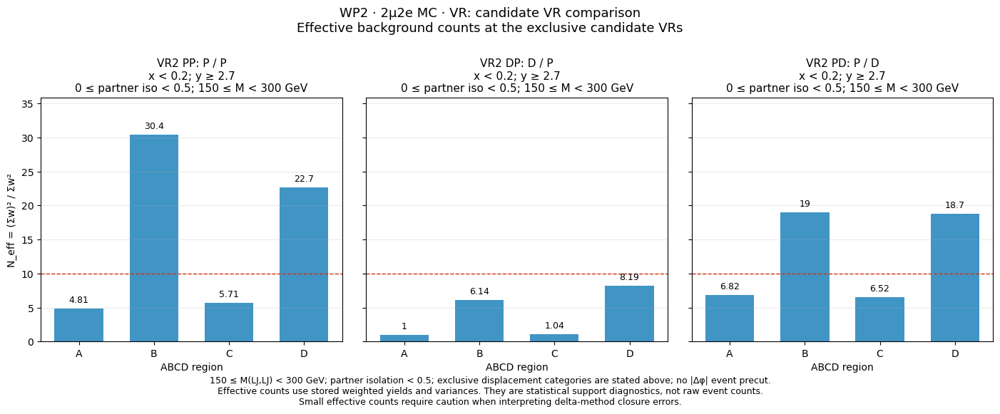

In [45]:
display(figure_lookup['wp2_mc_VR_effective_counts'])


### 5.15. DATA All/A/B/C/D correlations


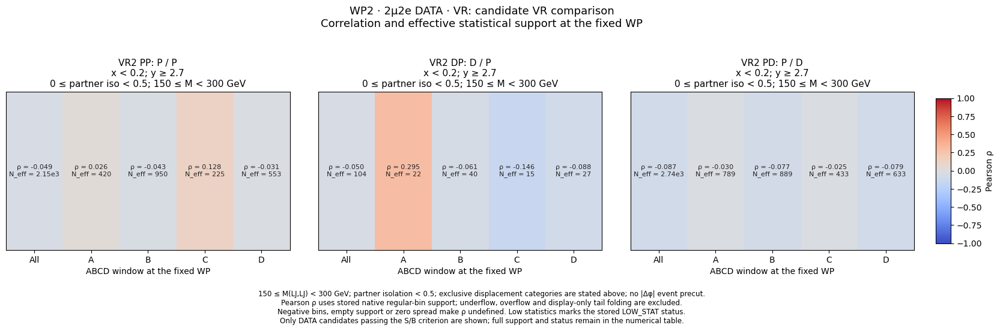

In [46]:
display(figure_lookup['wp2_data_VR_correlations'])


### 5.16. MC All/A/B/C/D correlations


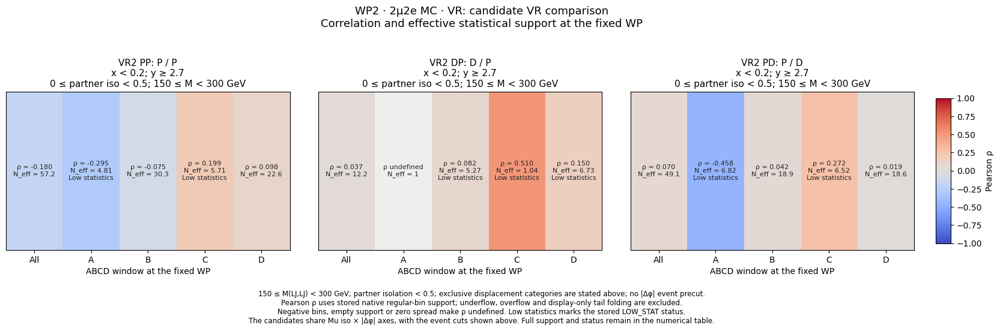

In [47]:
display(figure_lookup['wp2_mc_VR_correlations'])


### 5.17. Nominal MC SR at the same WP

Retain DD, Mjj≥150 GeV, and 0≤partner iso<0.5.
Exclude nominal DATA. Partition the SR using the same (0.20, 2.7) boundaries as the VR.


In [48]:
sr = results['points']['WP2']['sr_reference']
with pd.option_context('display.max_columns', None):
    display(sr['tables']['closure'][['plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                     'pred', 'pred_error', 'kappa', 'kappa_error',
                                     'neff_min', 'status']])


,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
49,SR,MC,0.2,2.7,2.162417,158.080993,11.924123,64.925895,29.03275,30.478389,0.074482,0.087588,1.760364,LOW_STAT_SIDEBAND


### 5.18. Nominal MC SR 2D distributions


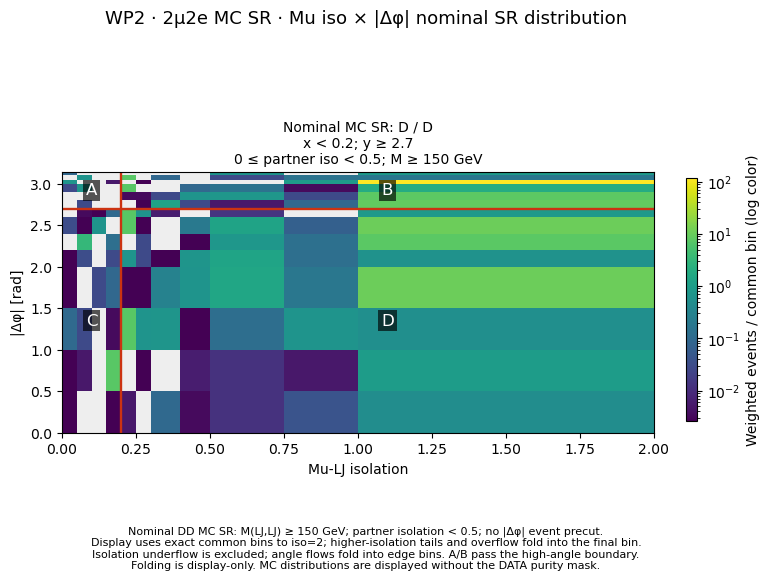

In [49]:
display(figure_lookup['wp2_mc_SR_planes'])


### 5.19. Nominal MC SR ABCD closure


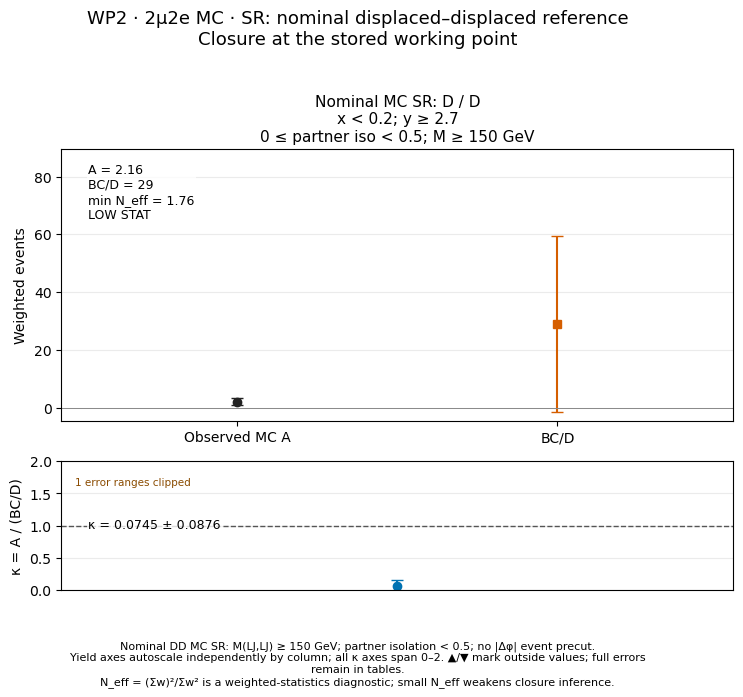

In [50]:
display(figure_lookup['wp2_mc_SR_selected_closure'])


### 5.20. Nominal MC SR isolation boundary scan


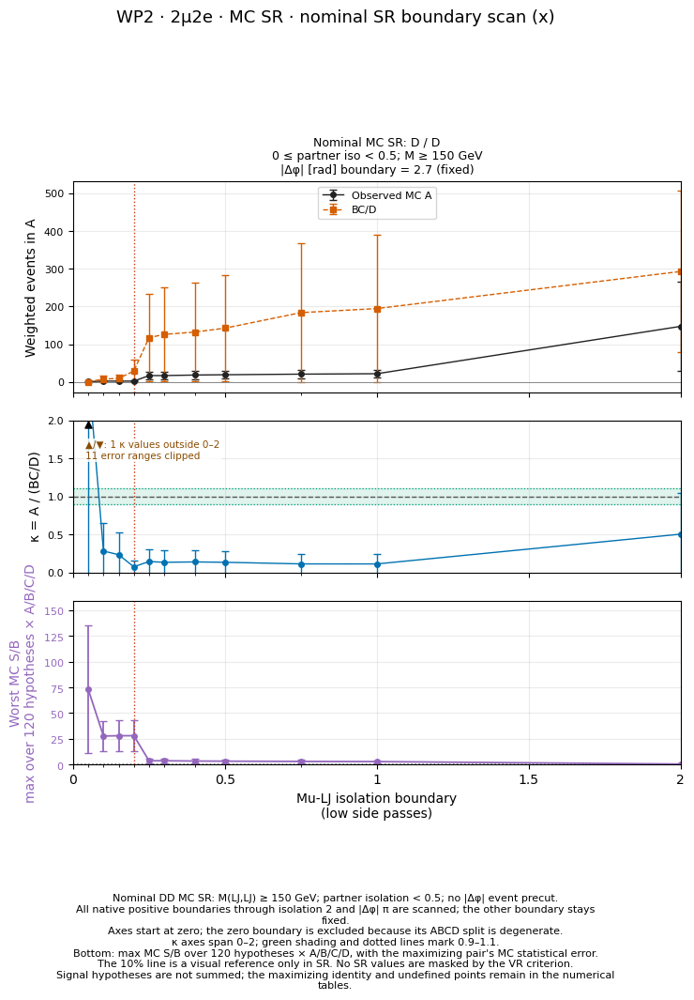

In [51]:
display(figure_lookup['wp2_mc_SR_x_scan'])


### 5.21. Nominal MC SR Δφ boundary scan


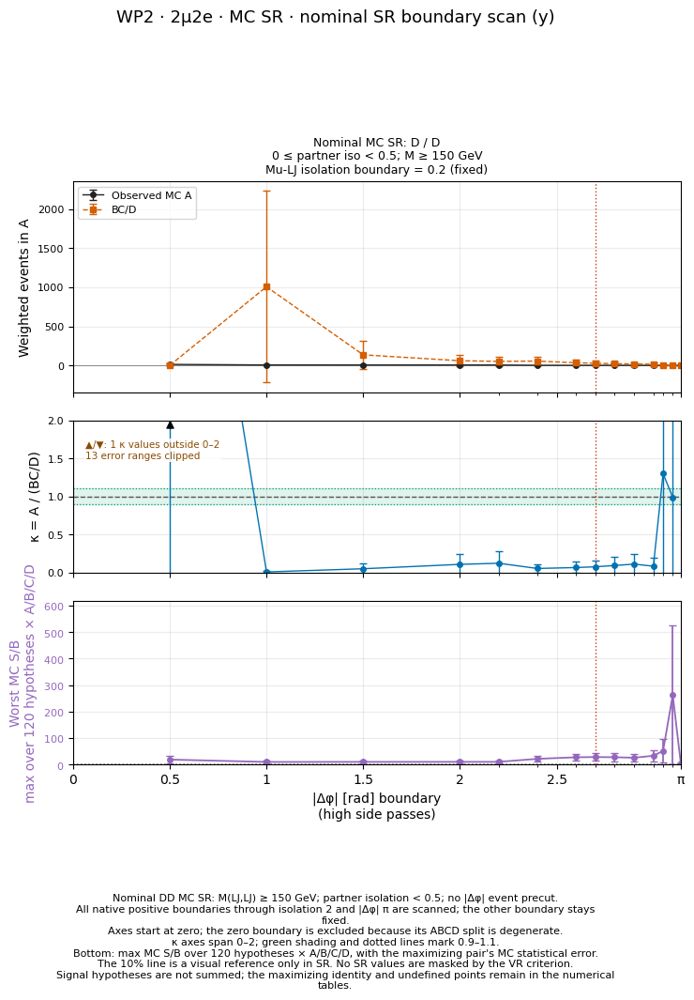

In [52]:
display(figure_lookup['wp2_mc_SR_y_scan'])


### 5.22. Nominal MC SR 154-point κ map


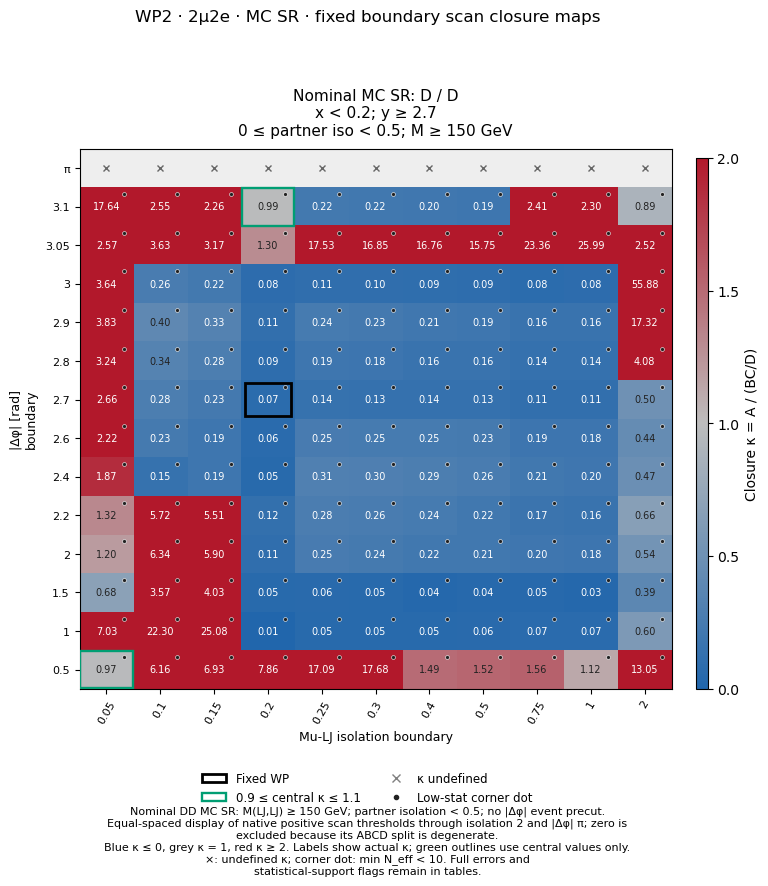

In [53]:
display(figure_lookup['wp2_mc_SR_closure_grid'])


## 6. WP3 — (mu iso, |Δφ|)=(0.20, 2.8)

Apply **the same (0.20, 2.8) boundaries to VR2 PP·DP·PD and the nominal MC SR** in this section.
Fix Δφ at **2.8** for the iso scan and iso at **0.20** for the Δφ scan.
The 154-point 2D κ map uses the shared scan; only the selected-WP marker changes.


In [54]:
point = results['points']['WP3']
with pd.option_context('display.max_columns', None):
    display(point['tables']['selection'][['plane', 'state0', 'state1', 'mass_low',
                                         'mass_high', 'partner_iso_high', 'tx', 'ty']])
    display(point['tables']['closure'][['plane', 'source', 'A', 'B', 'C', 'D',
                                       'pred', 'pred_error', 'kappa', 'kappa_error',
                                       'neff_min', 'approved', 'status']])


,plane,state0,state1,mass_low,mass_high,partner_iso_high,tx,ty
0,PP,P,P,150.0,300.0,0.5,0.2,2.8
1,DP,D,P,150.0,300.0,0.5,0.2,2.8
2,PD,P,D,150.0,300.0,0.5,0.2,2.8


,plane,source,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,approved,status
0,PP,MC,348.492231,1155.271389,269.379148,666.024489,467.259129,219.127924,0.745822,0.504452,4.209652,True,LOW_STAT_SIDEBAND
1,PP,DATA,358.000000,820.000000,287.000000,687.000000,342.561863,26.884967,1.045067,0.098883,287.000000,True,OK
2,DP,MC,7.327512,29.121208,3.334575,22.822972,4.254785,4.758898,1.722181,2.583846,1.000000,True,LOW_STAT_SIDEBAND
3,DP,DATA,20.000000,33.000000,17.000000,34.000000,16.500000,5.680850,1.212121,0.497617,17.000000,True,OK
4,PD,MC,191.769659,917.367996,446.271381,1248.042474,328.029767,166.211824,0.584611,0.377530,6.238706,True,LOW_STAT_SIDEBAND
5,PD,DATA,680.000000,755.000000,542.000000,768.000000,532.825521,35.630075,1.276215,0.098378,542.000000,True,OK


### 6.1. MC and DATA closure comparison at the fixed WP


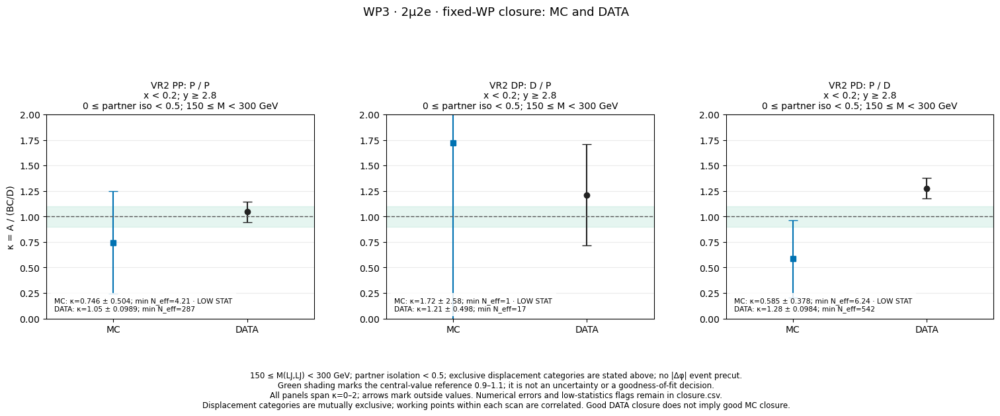

In [55]:
display(figure_lookup['wp3_combined_VR_selected_closure'])


### 6.2. Maximum S/B across 120 signals in each ABCD region


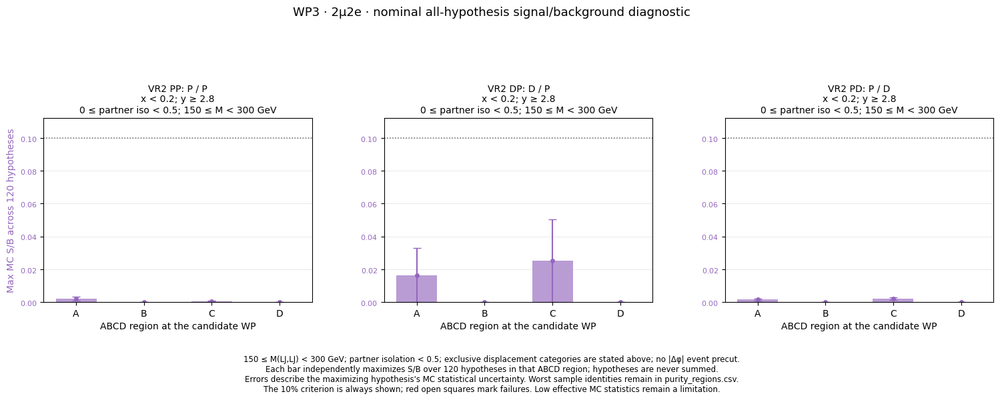

In [56]:
display(figure_lookup['wp3_mc_VR_purity_regions'])


### 6.3. DATA 2D distributions — bin-level blinding


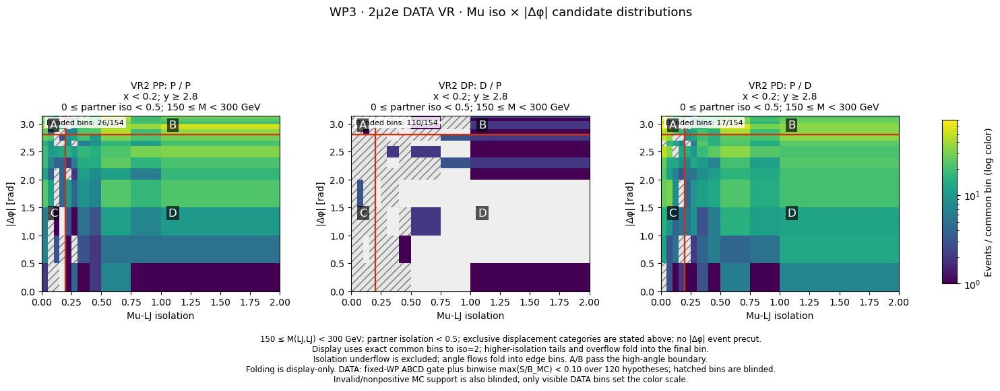

In [57]:
display(figure_lookup['wp3_data_VR_planes'])


### 6.4. DATA observed A, predicted BC/D, and κ


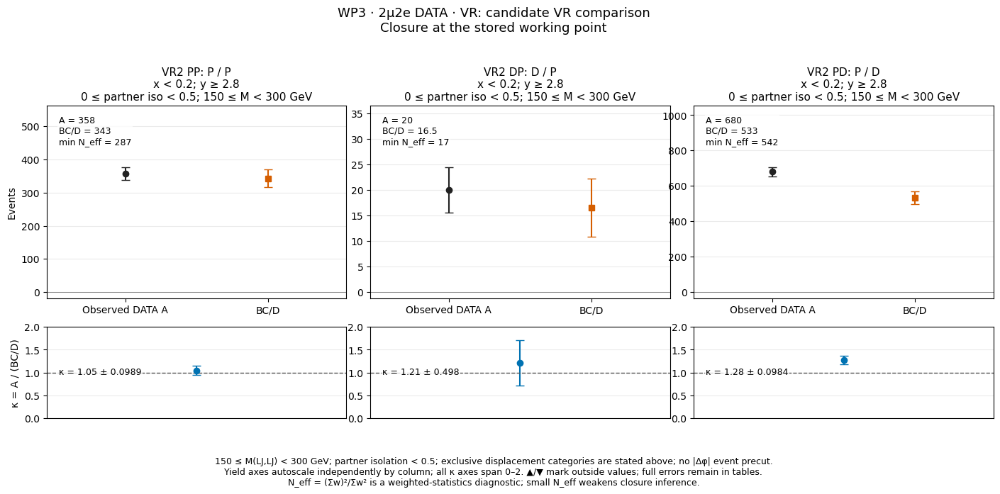

In [58]:
display(figure_lookup['wp3_data_VR_selected_closure'])


### 6.5. DATA isolation boundary scan


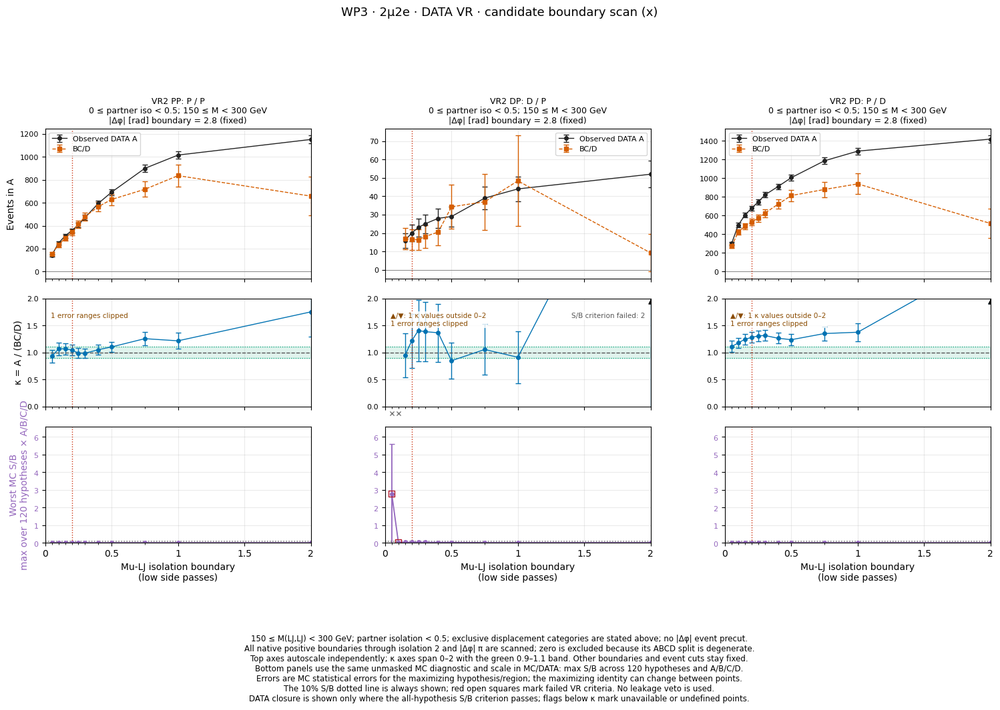

In [59]:
display(figure_lookup['wp3_data_VR_x_scan'])


### 6.6. DATA Δφ boundary scan


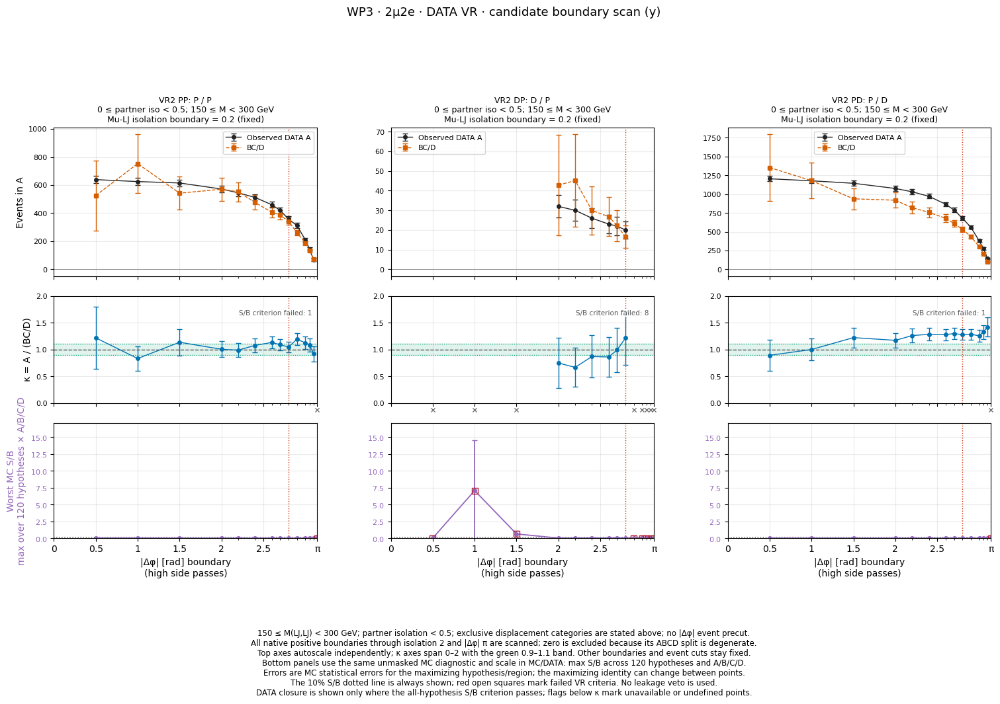

In [60]:
display(figure_lookup['wp3_data_VR_y_scan'])


### 6.7. DATA 154-point κ map


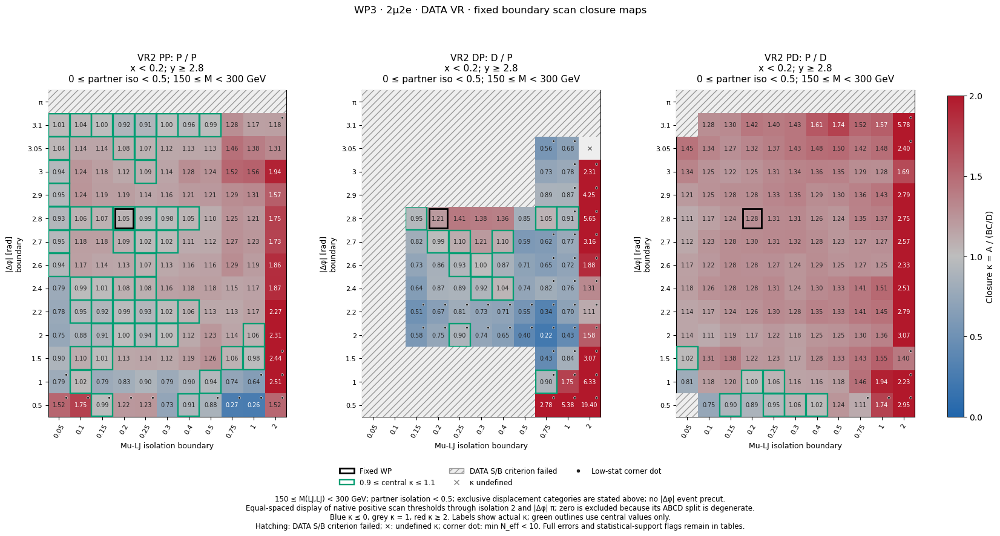

In [61]:
display(figure_lookup['wp3_data_VR_closure_grid'])


### 6.8. MC 2D distributions


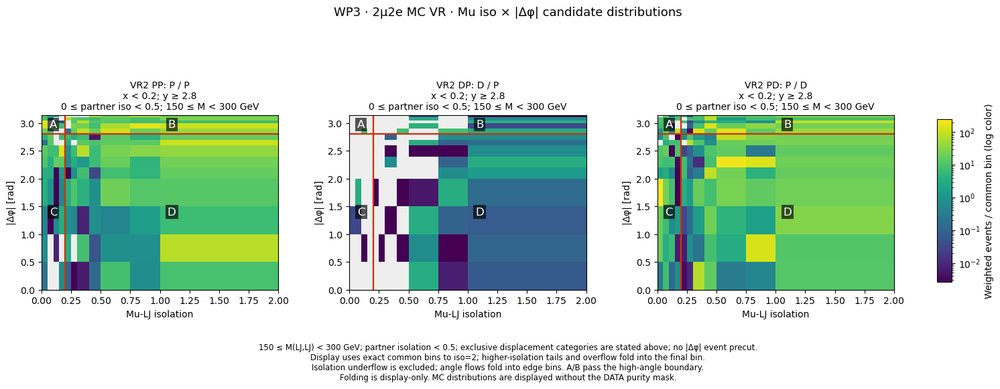

In [62]:
display(figure_lookup['wp3_mc_VR_planes'])


### 6.9. MC observed A, predicted BC/D, and κ


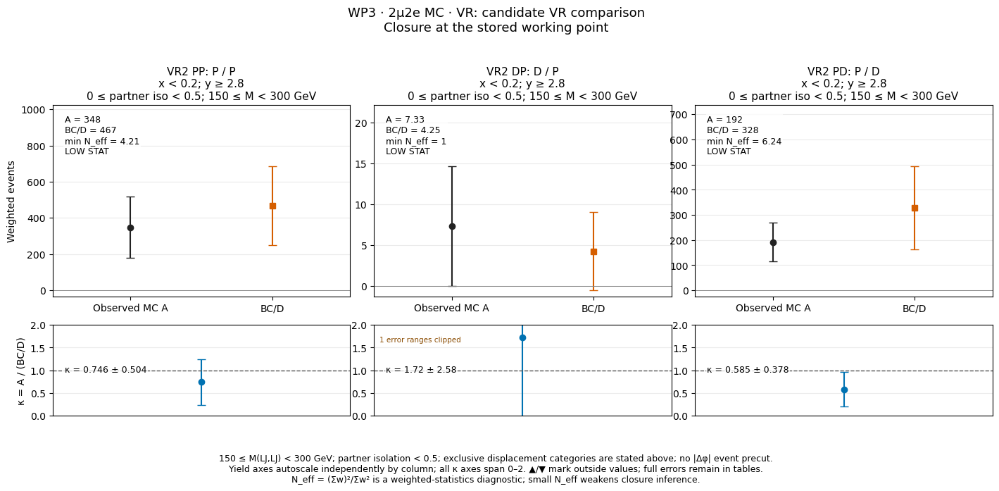

In [63]:
display(figure_lookup['wp3_mc_VR_selected_closure'])


### 6.10. MC isolation boundary scan


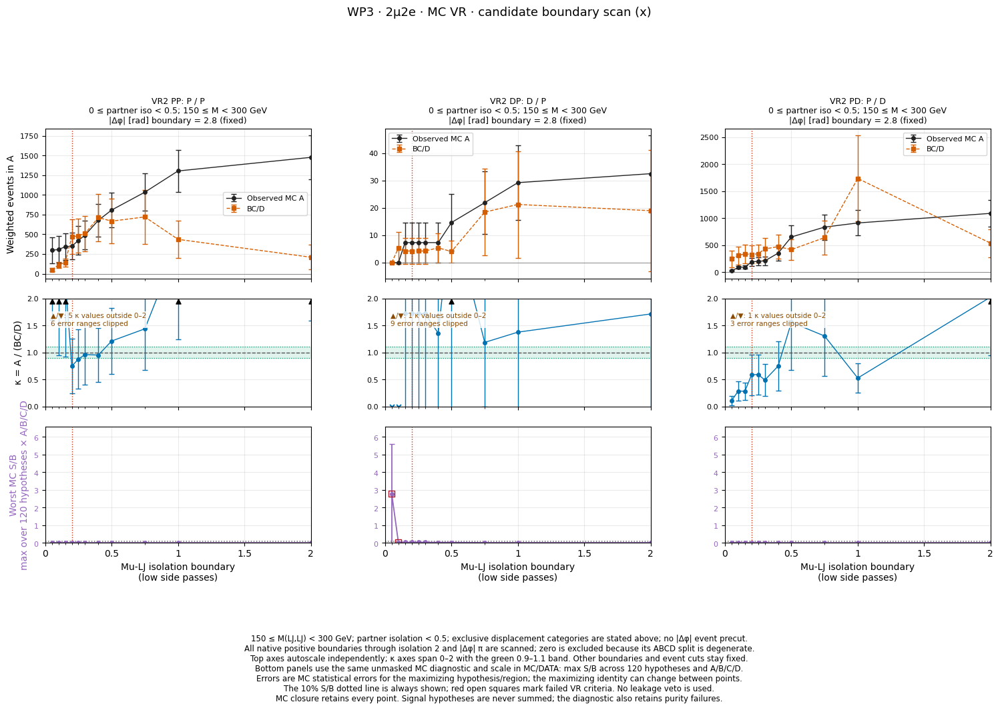

In [64]:
display(figure_lookup['wp3_mc_VR_x_scan'])


### 6.11. MC Δφ boundary scan


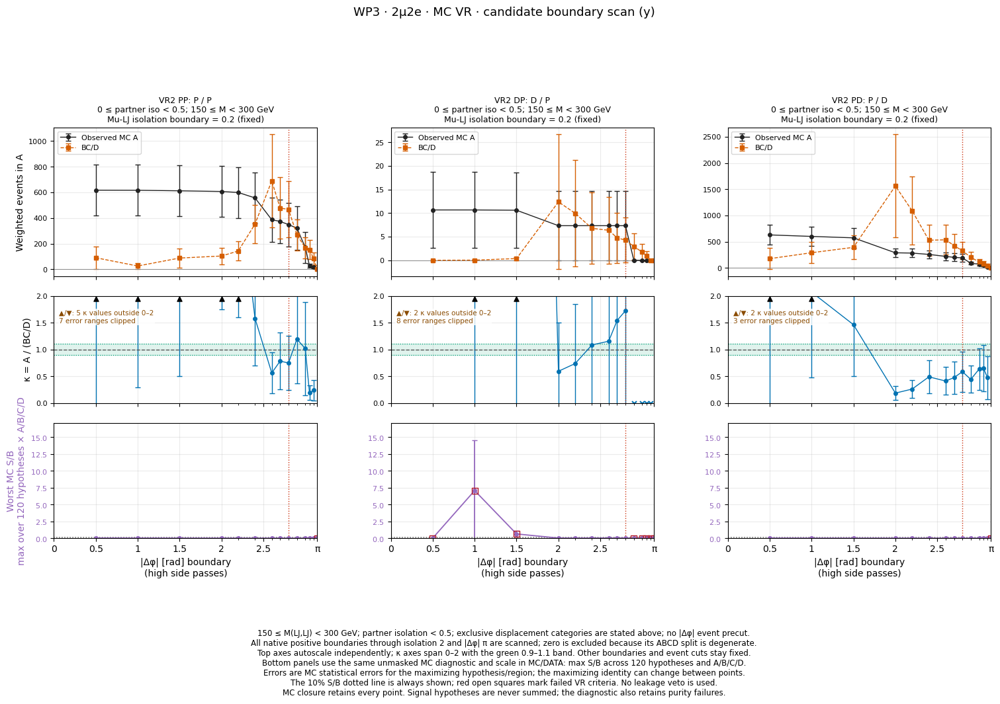

In [65]:
display(figure_lookup['wp3_mc_VR_y_scan'])


### 6.12. MC 154-point κ map


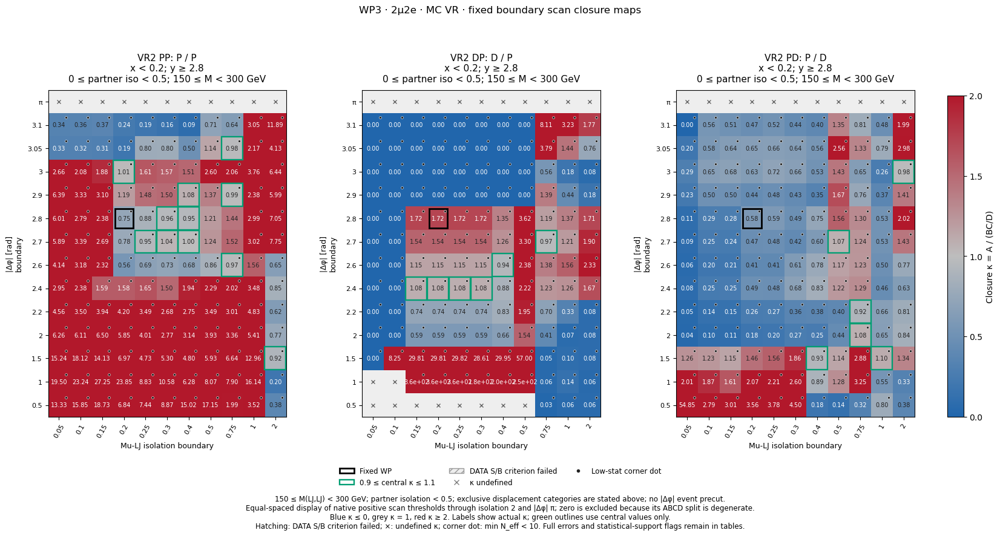

In [66]:
display(figure_lookup['wp3_mc_VR_closure_grid'])


### 6.13. MC background composition


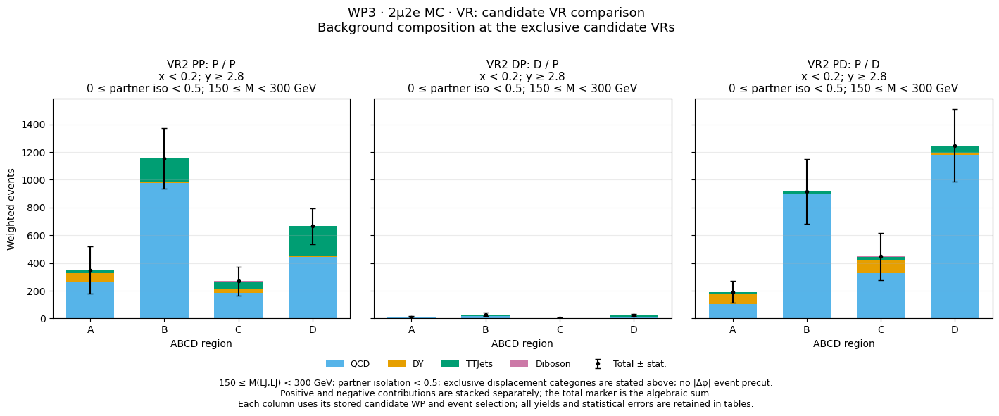

In [67]:
display(figure_lookup['wp3_mc_VR_composition'])


### 6.14. MC ABCD effective counts


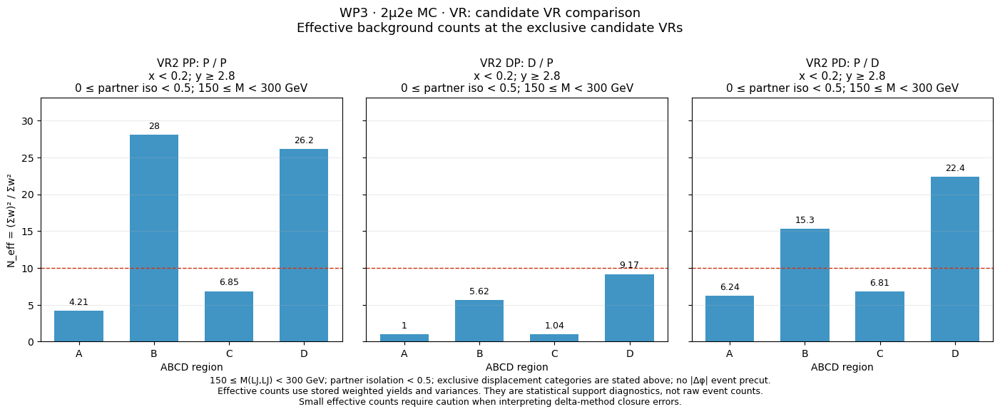

In [68]:
display(figure_lookup['wp3_mc_VR_effective_counts'])


### 6.15. DATA All/A/B/C/D correlations


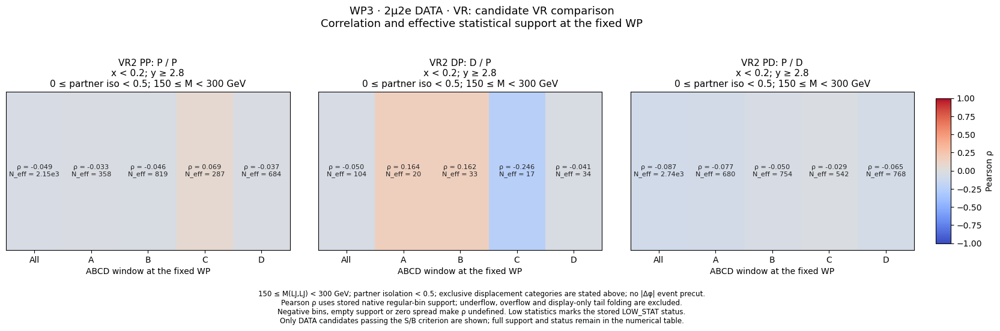

In [69]:
display(figure_lookup['wp3_data_VR_correlations'])


### 6.16. MC All/A/B/C/D correlations


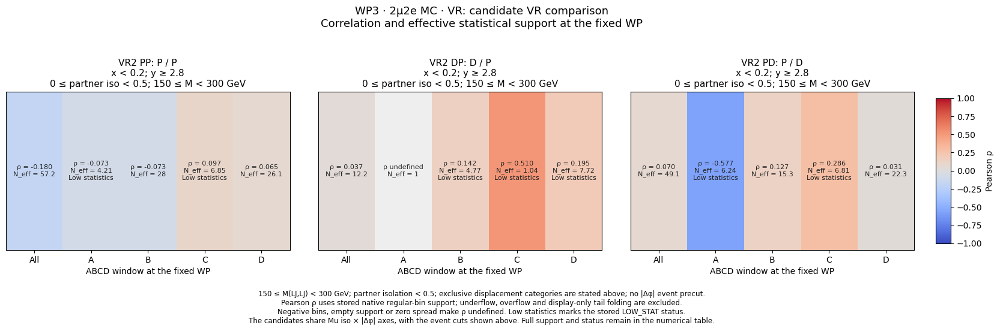

In [70]:
display(figure_lookup['wp3_mc_VR_correlations'])


### 6.17. Nominal MC SR at the same WP

Retain DD, Mjj≥150 GeV, and 0≤partner iso<0.5.
Exclude nominal DATA. Partition the SR using the same (0.20, 2.8) boundaries as the VR.


In [71]:
sr = results['points']['WP3']['sr_reference']
with pd.option_context('display.max_columns', None):
    display(sr['tables']['closure'][['plane', 'source', 'tx', 'ty', 'A', 'B', 'C', 'D',
                                     'pred', 'pred_error', 'kappa', 'kappa_error',
                                     'neff_min', 'status']])


,plane,source,tx,ty,A,B,C,D,pred,pred_error,kappa,kappa_error,neff_min,status
50,SR,MC,0.2,2.8,2.133242,147.488067,11.953298,75.518821,23.34476,25.262082,0.09138,0.110391,1.538358,LOW_STAT_SIDEBAND


### 6.18. Nominal MC SR 2D distributions


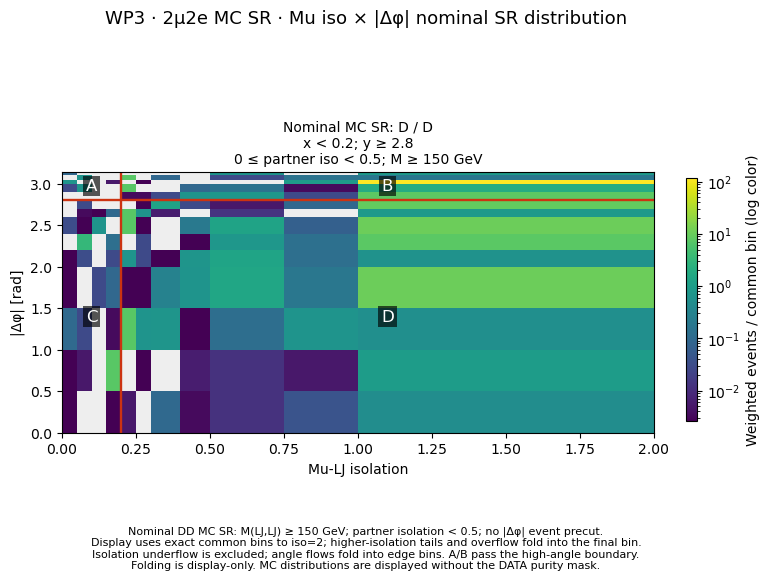

In [72]:
display(figure_lookup['wp3_mc_SR_planes'])


### 6.19. Nominal MC SR ABCD closure


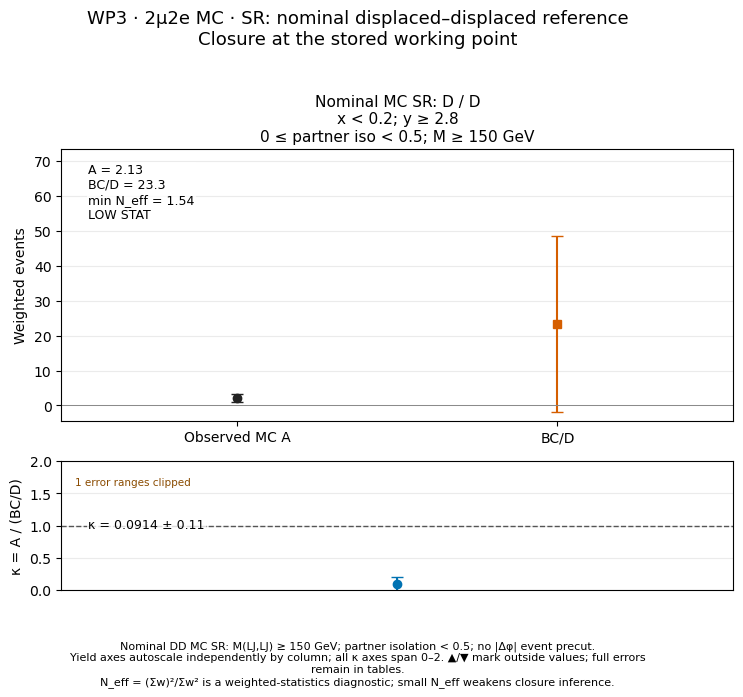

In [73]:
display(figure_lookup['wp3_mc_SR_selected_closure'])


### 6.20. Nominal MC SR isolation boundary scan


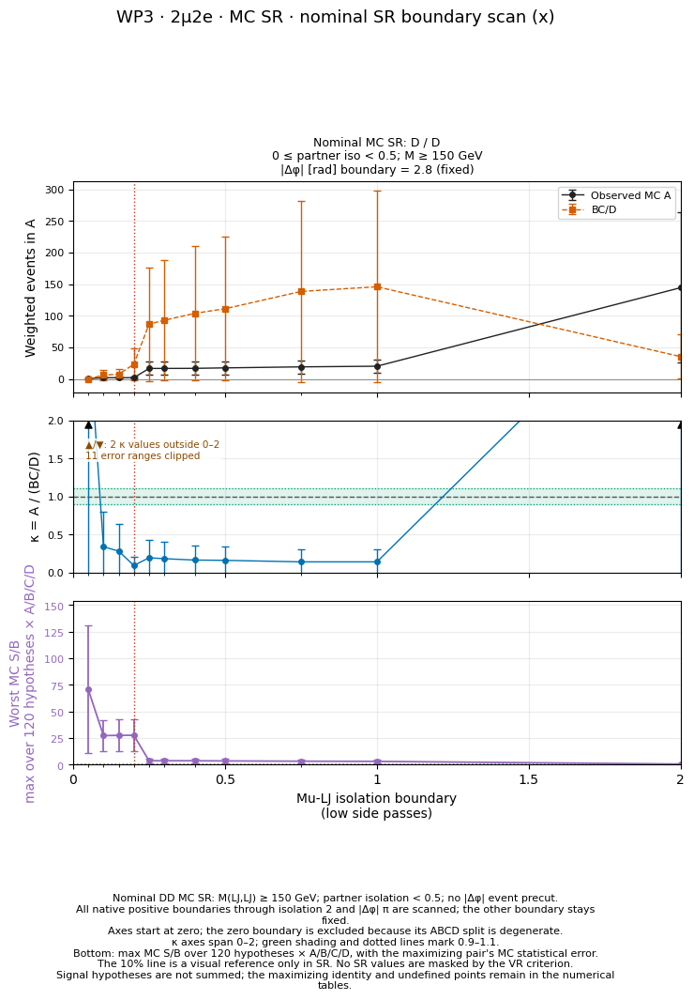

In [74]:
display(figure_lookup['wp3_mc_SR_x_scan'])


### 6.21. Nominal MC SR Δφ boundary scan


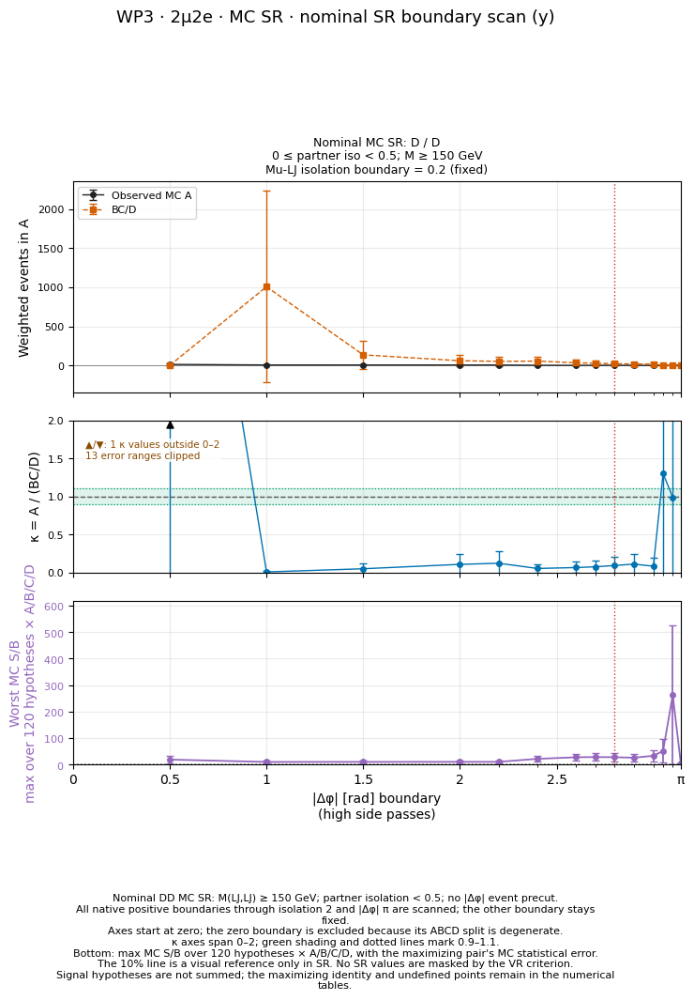

In [75]:
display(figure_lookup['wp3_mc_SR_y_scan'])


### 6.22. Nominal MC SR 154-point κ map


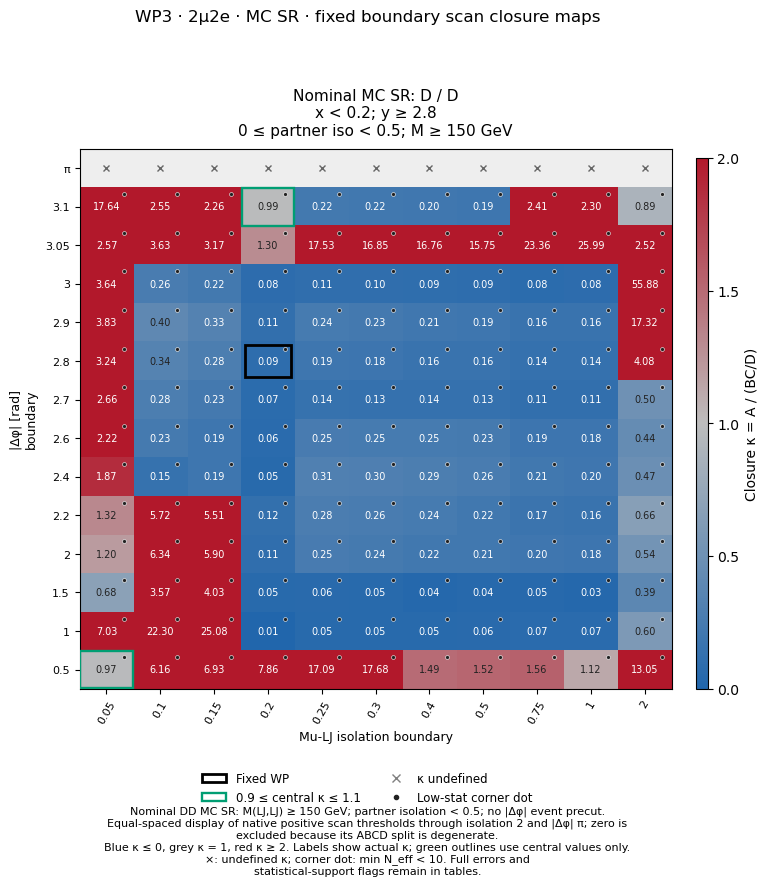

In [76]:
display(figure_lookup['wp3_mc_SR_closure_grid'])


## 7. Validation and export

Check that the SR and VR boundaries match for every WP, that each scan holds the other axis fixed,
and that the full grid agrees with the directly summed ABCD yields. Also check the DATA gate and displayed-bin mask.
Retain the original reference's MC SR regression and native-bin partition checks.

Save three summary PNGs, a complete 66-page slide PDF containing every figure,
the reference and three WP results, per-signal significance, purity, and input manifests in this notebook's dedicated outputs folder.
Do not record masked 2D DATA bin values in new audit tables.

Preserve all 66 figures in both this notebook and the full vector PDF. Save only the three summary PNGs separately at 100dpi; do not duplicate WP-specific PNGs or individual PDFs. Recalculate the full 154-point signal grid from the original inputs without creating duplicate CSVs. Save the per-hypothesis results for all 120 signals at the reference and the three WPs in `signal_significance.csv`.


In [77]:
export_wp_comparison(results, CONFIG, figures)
display(Markdown(f'[PNG figure index]({OUTPUT_DIR.name}/figure_manifest.csv)'))
display(Markdown(f'[Output directory]({OUTPUT_DIR.name}/)'))


Saved: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_finalize/05_2mu2e_WP_comparison_outputs


[PNG figure index](05_2mu2e_WP_comparison_outputs/figure_manifest.csv)

[Output directory](05_2mu2e_WP_comparison_outputs/)

## Interpretation limits

In the current production, the sensitivity gain at iso=0.20 is largely driven by removing a QCD contribution with large weights.
Inspect this together with the small effective background MC counts in the SR and the κ deviation in VR PD.

The three WPs are candidates for further review, not a final analysis WP choice.
Good DATA closure alone does not guarantee MC closure or the stability of the nominal ABCD estimate.
These WPs share events with the existing reference, so do not interpret their numerical differences as independent statistical tests.
